# Разведочный анализ nowcasting роста ВРП регионов России

Главная зависимая переменная индекс физического объема валового регионального продукта (ИФО ВРП) - это относительный статистический показатель, который отражает, как изменился реальный объем производства товаров и услуг в регионе по сравнению с предыдущим годом, исключая влияние изменения цен (инфляции).

Вопросы для EDA:

1. Как устроена цель (ИФО ВРП, г/г): сколько наблюдений, где пропуски, как склеены ОКВЭД-2007 и ОКВЭД2, какой разброс и что в нём от общих годовых шоков, а что от региона.
2. Какие признаки есть в обучающем окне, а какие появляются только к валидации или тесту.
3. Где в признаках нули, выбросы и разрывы методологии.
4. Какие месячные ряды после агрегации до года связаны с ростом ВРП, и держится ли эта связь при переходе от обучения к валидации.
5. Есть ли зависимости роста ВРП с другими признаками.

Предварительно период обучения - 2005-2016, период валидации - 2017-2021, период теста - 2022-2024.

Данные для панели были собраны в основном из двух источников: [ЦБ РФ](https://www.cbr.ru) и [ЕМИСС](https://www.fedstat.ru).

In [1]:
import pathlib
import warnings

import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)
pd.set_option('display.max_colwidth', 60)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

In [3]:
root = pathlib.Path.cwd()
path_processed = root / 'data/processed'
path_reference = root / 'data/reference'

train_years = (2005, 2016)
val_years = (2017, 2021)
test_years = (2022, 2024)

rng = np.random.default_rng(42)

In [4]:
# цвета для графиков
color_main = '#2E5A87'
color_accent = '#D1495B'
color_grey = '#9AA5B1'
color_second = '#E9A23B'
period_colors = {'обучение': '#2E5A87', 'валидация': '#E9A23B', 'тест': '#D1495B'}

plt.style.use('seaborn-v0_8-whitegrid')
mpl.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150, 'axes.titlesize': 12,
                     'axes.titleweight': 'bold', 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})

In [5]:
periods = [(train_years, 'обучение'), (val_years, 'валидация'), (test_years, 'тест')]


def get_period(year):
    if train_years[0] <= year <= train_years[1]:
        return 'обучение'
    elif val_years[0] <= year <= val_years[1]:
        return 'валидация'
    elif test_years[0] <= year <= test_years[1]:
        return 'тест'
    else:
        return 'вне окна'


def shade_periods(ax, alpha=0.08):
    for years, label in periods:
        ax.axvspan(years[0] - 0.5, years[1] + 0.5, color=period_colors[label], alpha=alpha, lw=0)

## 1. Состав датасета

Загружаю все таблицы `data/processed/` и справочник регионов. Для каждой таблицы проверяю гранулярность, уникальность ключа и охват по времени.

In [6]:
regions = pd.read_csv(path_reference / 'regions.csv')
region_geo = pd.read_csv(path_reference / 'region_geo.csv')
adjacency = pd.read_csv(path_reference / 'adjacency_long.csv')
catalog = pd.read_csv(path_processed / 'feature_catalog.csv', sep=';')

In [7]:
sample_regions = regions[regions['in_sample']].copy()
sample_ids = set(sample_regions['region_id'])
region_names = sample_regions.set_index('region_id')['name_short'].to_dict()
region_fd = sample_regions.set_index('region_id')['fd'].to_dict()
print(f'Единиц в выборке: {sample_regions.shape[0]}', f'Федеральных округов: {sample_regions["fd"].nunique()}', sep='\n')

Единиц в выборке: 85
Федеральных округов: 8


In [8]:
monthly_long = pd.read_parquet(path_processed / 'features_regional_monthly_long.parquet')
annual_wide = pd.read_parquet(path_processed / 'features_regional_annual_wide.parquet')
national_monthly = pd.read_parquet(path_processed / 'features_national_monthly_wide.parquet')
national_annual = pd.read_parquet(path_processed / 'features_national_annual_long.parquet')
target_wide = pd.read_parquet(path_processed / 'target_grp_wide.parquet')

In [9]:
tables = {'features_regional_monthly_long': [monthly_long, ['feature', 'region_id', 'year', 'month'], 'регион x месяц x признак'],
          'features_regional_annual_wide': [annual_wide, ['region_id', 'year'], 'регион x год'],
          'features_national_monthly_wide': [national_monthly, ['year', 'month'], 'месяц'],
          'features_national_annual_long': [national_annual, ['feature', 'year'], 'год x признак'],
          'target_grp_wide': [target_wide, ['region_id', 'year'], 'регион x год']}

profile = pd.DataFrame(columns=['строк', 'признаков', 'гранулярность', 'дублей ключа', 'годы', 'регионов'])
for name in tables:
    df, key, grain = tables[name]
    if 'feature' in df.columns:
        n_features = df['feature'].nunique()
    else:
        n_features = df.shape[1] - len(key)
    if 'region_id' in df.columns:
        n_regions = df['region_id'].nunique()
    else:
        n_regions = '—'
    years = f'{int(df["year"].min())}–{int(df["year"].max())}'
    profile.loc[name] = [df.shape[0], n_features, grain, df.duplicated(key).sum(), years, n_regions]
profile.index.name = 'таблица'
profile

/var/folders/pl/w92ryc8967j8drzryhgv2l900000gn/T/ipykernel_54954/1045561869.py:19: Pandas4Warning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. The existing dtype int64 cannot hold the value being set, so the result has dtype object. Cast the object to object before this operation to retain the current behavior.
  profile.loc[name] = [df.shape[0], n_features, grain, df.duplicated(key).sum(), years, n_regions]


,строк,признаков,гранулярность,дублей ключа,годы,регионов
таблица,,,,,,
features_regional_monthly_long,1689800,119,регион x месяц x признак,0,1999–2026,103
features_regional_annual_wide,3002,62,регион x год,0,1990–2025,85
features_national_monthly_wide,816,126,месяц,0,1960–2027,—
features_national_annual_long,24,2,год x признак,0,2002–2025,—
target_grp_wide,2314,38,регион x год,0,1997–2024,85


Ключи уникальны во всех пяти таблицах. Таблицы кроме основной выборки содержат строки РФ и федеральных округов, поэтому регионов в них больше 85; дальше я везде фильтрую по флагу `in_sample` только регионы РФ, без агрегации РФ и федеральных округов.

In [10]:
catalog.groupby(['table', 'group']).size().to_frame('признаков')

признаков
table            group                                             
national_annual  8. Ограничение для согласования                  2
national_monthly 1. Официальная месячная статистика (РФ)          6
                 2. Опросы                                        6
                 3. Финансы и кредит                             14
                 5. Сырьевые цены и отраслевые шоки              95
                 7. Календарь и шоки                              3
                 8. Ограничение для согласования                  2
regional_annual  1. Официальная статистика (год)                 17
                 6. Структурные признаки                         45
regional_monthly 1. Официальная месячная статистика              74
                 3. Финансы и кредит                             17
                 4. Бюджет и налоги                              28
target           Цель                                             2
                 Цель (multi-task)                               36

## 2. Целевая переменная

Цель в датасете лежит двумя рядами: `grp_okved1_yoy` (ОКВЭД-2007, 1997–2016) и `grp_yoy` (ОКВЭД2, 2017–2024). Они не пересекаются ни в одном году, поэтому склейка такая: до 2016 года беру первый ряд, с 2017 второй. Перевожу индекс в проценты прироста: `g = ИФО − 100`, единица измерения - процентные пункты.

In [11]:
grp = target_wide.copy()
grp['year'] = grp['year'].astype(int)
both = grp[['grp_okved1_yoy', 'grp_yoy']].notna().all(axis=1).sum()
print('Лет, где заполнены оба ряда:', both)

Лет, где заполнены оба ряда: 0


In [12]:
grp['source'] = np.where(grp['grp_yoy'].notna(), 'ОКВЭД2', np.where(grp['grp_okved1_yoy'].notna(), 'ОКВЭД-2007', None))
grp['ifo'] = grp['grp_yoy'].fillna(grp['grp_okved1_yoy'])

zeros = grp[grp['region_id'].isin(sample_ids) & (grp['ifo'] == 0)].copy()
zeros['name'] = zeros['region_id'].map(region_names)
print('Нулевых значений ИФО ВРП в выборке:', zeros.shape[0])
zeros.groupby('name')['year'].agg(['min', 'max', 'count'])

Нулевых значений ИФО ВРП в выборке: 21


,min,max,count
name,,,
Ненецкий АО,1997,2000,4
Ханты-Мансийский АО - Югра,1997,2000,4
Чеченская Республика,1997,2005,9
Ямало-Ненецкий АО,1997,2000,4


Ноль в индексе физического объёма - это пропуск, записанный в источнике (ЕМИСС) нулём. Нули стоят у четырёх автономных округов за 1997–2000 годы (тогда Росстат не выделял их из областей) и у Чечни за 1997–2005 годы. 2005 год Чечни попадает в обучающее окно, так что без замены на пропуск модель получила бы падение ВРП на 100%. Заменяю нули на NaN.

In [13]:
grp.loc[grp['ifo'] == 0, 'ifo'] = np.nan
grp['g'] = grp['ifo'] - 100

grp_sample = grp[grp['region_id'].isin(sample_ids)].copy()
grp_sample['name'] = grp_sample['region_id'].map(region_names)
grp_sample['fd'] = grp_sample['region_id'].map(region_fd)
grp_sample['period'] = grp_sample['year'].map(get_period)

In [14]:
missing = grp_sample[(grp_sample['year'] >= train_years[0]) & grp_sample['g'].isna()]
print('Пропуски цели с 2005 года:')
missing.groupby('name')['year'].agg(['min', 'max'])

Пропуски цели с 2005 года:


,min,max
name,,
Чеченская Республика,2005,2005


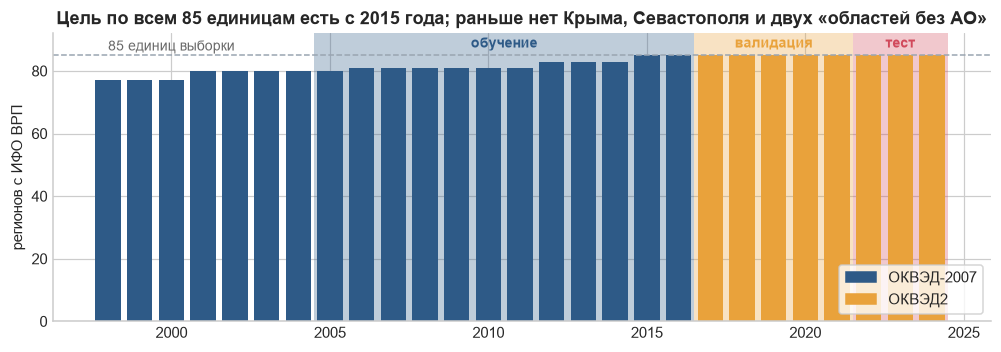

In [15]:
coverage_target = grp_sample[grp_sample['year'] >= 1998].groupby('year').agg(regions=('g', 'count'), source=('source', 'first'))

bar_colors = []
for s in coverage_target['source']:
    if s == 'ОКВЭД-2007':
        bar_colors.append(color_main)
    else:
        bar_colors.append(color_second)

fig, ax = plt.subplots(figsize=(11, 3.4))
shade_periods(ax, 0.3)
ax.bar(coverage_target.index, coverage_target['regions'], color=bar_colors)
ax.axhline(85, color=color_grey, ls='--', lw=1)
for years, label in periods:
    ax.text((years[0] + years[1]) / 2, ax.get_ylim()[1] * 0.98, label, ha='center', color=period_colors[label], fontsize=9, fontweight='bold')
ax.text(1998, 86.5, '85 единиц выборки', color='dimgray', fontsize=9)
ax.set_ylim(0, 92)
ax.set_ylabel('регионов с ИФО ВРП')
ax.set_title('Цель по всем 85 единицам есть с 2015 года; раньше нет Крыма, Севастополя и двух «областей без АО»')
ax.legend(handles=[mpl.patches.Patch(color=color_main, label='ОКВЭД-2007'), mpl.patches.Patch(color=color_second, label='ОКВЭД2')],
          loc='lower right', frameon=True)
plt.show()

С 2005 года цель есть у 80–85 единиц из 85. Все пропуски объясняются составом выборки, а не качеством данных: Крым и Севастополь появляются в 2015 году, Тюменская область без ХМАО и ЯНАО и Архангельская область без НАО в 2012 году, у Чечни нет 2005 года (в источнике - ноль). В обучающем окне 985 наблюдений «регион-год».

Панель несбалансированная, и это надо учесть в моделях: модели с фиксированными эффектами региона должны принимать пропуски, а не выбрасывать регион целиком.

### 2.1. Динамика и разброс по годам

График показывает, как распределён рост ВРП по регионам в каждом году: медиана, межквартильный размах и 10–90 перцентили. Для сравнения изображен рост ВВП России и ряд ИФО ВРП для РФ в целом из того же источника.

In [16]:
gdp = national_annual.pivot(index='year', columns='feature', values='value')
gdp.index = gdp.index.astype(int)
gdp_growth = gdp['gdp_yoy_y'].fillna(gdp['gdp_old_yoy_y']) - 100

In [17]:
target_long = pd.read_parquet(path_processed / 'target_grp_long.parquet')
rf_rows = target_long[target_long['feature'].isin(['grp_yoy', 'grp_okved1_yoy']) & target_long['region_id'].str.startswith('rossiyskaya_federatsiya')].copy()
rf_rows['year'] = rf_rows['year'].astype(int)
rf_rows = rf_rows.pivot_table(index='year', columns='region_id', values='value')

# с 2023 года Росстат даёт строку «РФ без учёта новых субъектов»
rf_grp_growth = rf_rows['rossiyskaya_federatsiya'].fillna(rf_rows['rossiyskaya_federatsiya_bez_ucheta_novykh_subektov_s_01_01_2023']) - 100

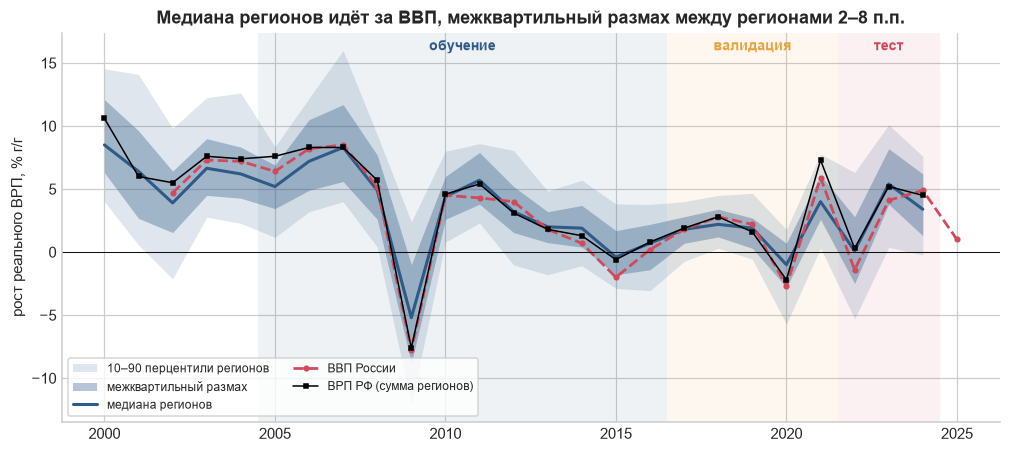

In [18]:
quantiles = grp_sample[grp_sample['year'] >= 2000].groupby('year')['g'].quantile([0.1, 0.25, 0.5, 0.75, 0.9]).unstack()

fig, ax = plt.subplots(figsize=(11, 4.6))
shade_periods(ax)
ax.fill_between(quantiles.index, quantiles[0.1], quantiles[0.9], color=color_main, alpha=0.15, lw=0, label='10–90 перцентили регионов')
ax.fill_between(quantiles.index, quantiles[0.25], quantiles[0.75], color=color_main, alpha=0.35, lw=0, label='межквартильный размах')
ax.plot(quantiles.index, quantiles[0.5], color=color_main, lw=2, label='медиана регионов')
ax.plot(gdp_growth.loc[2000:].index, gdp_growth.loc[2000:], color=color_accent, lw=1.8, ls='--', marker='o', ms=3, label='ВВП России')
ax.plot(rf_grp_growth.loc[2000:].index, rf_grp_growth.loc[2000:], color='black', lw=1, marker='s', ms=3, label='ВРП РФ (сумма регионов)')
ax.axhline(0, color='black', lw=0.6)
for years, label in periods:
    ax.text((years[0] + years[1]) / 2, ax.get_ylim()[1] * 0.92, label, ha='center', color=period_colors[label], fontsize=9, fontweight='bold')
ax.set_ylabel('рост реального ВРП, % г/г')
ax.set_title('Медиана регионов идёт за ВВП, межквартильный размах между регионами 2–8 п.п.')
ax.legend(loc='lower left', fontsize=8, ncol=2, frameon=True)
plt.show()

In [19]:
grp_2005 = grp_sample[grp_sample['year'] >= 2005]

dispersion = pd.DataFrame()
dispersion['медиана'] = grp_2005.groupby('year')['g'].median()
dispersion['std'] = grp_2005.groupby('year')['g'].std()
dispersion['IQR'] = grp_2005.groupby('year')['g'].quantile(0.75) - grp_2005.groupby('year')['g'].quantile(0.25)
dispersion['n'] = grp_2005.groupby('year')['g'].count()
dispersion['ВВП'] = gdp_growth
dispersion['ВРП РФ'] = rf_grp_growth
dispersion.T

year,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
медиана,5.20,7.20,8.30,4.90,-5.20,4.40,5.70,3.20,2.00,1.90,-0.40,0.70,1.80,2.20,1.90,-1.00,4.00,0.10,5.40,3.40
std,3.67,3.50,5.35,4.49,6.73,4.26,3.54,3.72,4.06,3.85,2.91,2.82,2.49,2.61,2.38,3.25,3.62,4.59,4.61,4.24
IQR,3.45,5.60,6.10,5.10,7.80,3.40,4.10,3.65,2.45,3.30,3.50,3.60,2.10,2.20,2.40,3.50,3.50,5.30,4.40,4.90
n,80.00,81.00,81.00,81.00,81.00,81.00,81.00,83.00,83.00,83.00,85.00,85.00,85.00,85.00,85.00,85.00,85.00,85.00,85.00,85.00
ВВП,6.40,8.20,8.50,5.20,-7.80,4.50,4.30,4.00,1.80,0.70,-2.00,0.20,1.80,2.80,2.20,-2.70,5.90,-1.40,4.10,4.90
ВРП РФ,7.60,8.30,8.30,5.70,-7.60,4.60,5.40,3.10,1.80,1.30,-0.60,0.80,1.90,2.80,1.60,-2.20,7.30,0.30,5.20,4.50


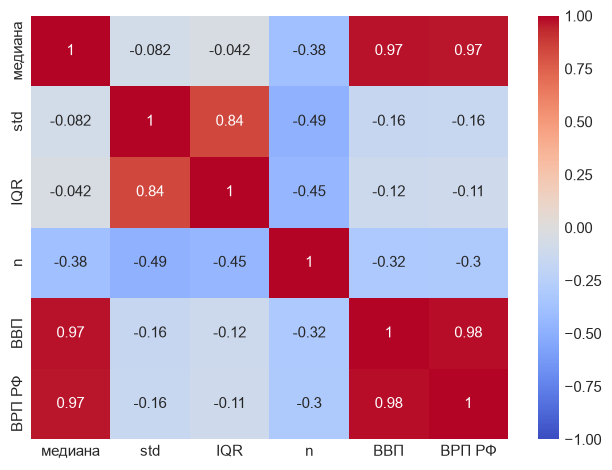

In [20]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(dispersion.corr(), vmax=1, vmin=-1, cmap='coolwarm', annot=True, ax=ax)
plt.show()

Медиана регионов идёт за ВВП почти год в год (корреляция 0,97). Межрегиональный разброс в годы без шоков держится около 2,4–2,6 п.п. (стандартное отклонение, 2017–2019), а в кризисы растёт: 6,7 п.п. в 2009 году, 4,6 п.п. в 2022–2023 годах. Значит, ошибка любой модели будет выше как раз в этих годах.

Для вопроса EDA 1 важна еще одна деталь. Рост ВРП РФ (сумма регионов) расходится с ВВП больше всего в переломные годы. В 2015 и 2022 годах сумма ВРП упала слабее ВВП на 1,4 и 1,7 п.п., в 2021 году выросла сильнее на 1,4 п.п. Во всех четырёх годах спада (2009, 2015, 2020, 2022) ВРП падал слабее. Поэтому нельзя ставить как равенство ВРП РФ и ВВП, для предсказания ВВП разницу «ВРП минус ВВП» придётся моделировать отдельно.

### 2.2. Распределение цели по периодам

In [21]:
from scipy import stats

In [22]:
grp_periods = grp_sample[grp_sample['year'].between(train_years[0], test_years[1])]

desc = pd.DataFrame(index=['обучение', 'валидация', 'тест'], columns=['n', 'mean', 'std', 'median', 'p1', 'p99', 'skew', 'kurt'])
for p in desc.index:
    s = grp_periods[grp_periods['period'] == p]['g'].dropna()
    desc.loc[p] = [s.shape[0], s.mean(), s.std(), s.median(), s.quantile(0.01), s.quantile(0.99), stats.skew(s), stats.kurtosis(s)]
desc = desc.astype(float)
desc

,n,mean,std,median,p1,p99,skew,kurt
обучение,985.00,3.24,5.44,3.40,-12.92,16.33,-0.25,2.33
валидация,425.00,1.85,3.43,1.80,-6.76,12.48,0.34,4.01
тест,255.00,3.38,5.03,3.60,-8.42,18.60,0.46,2.20


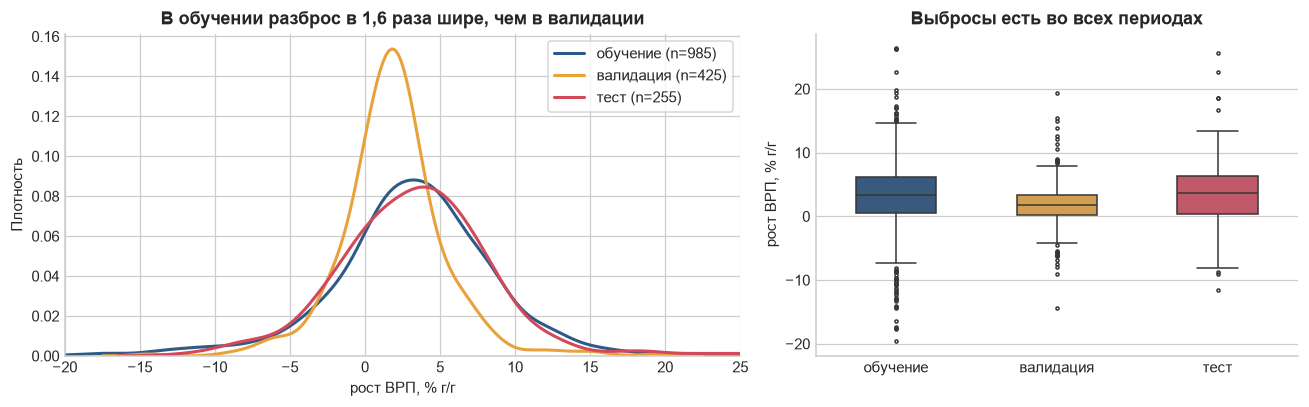

In [23]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={'width_ratios': [1.4, 1]})
for p in ['обучение', 'валидация', 'тест']:
    s = grp_periods[grp_periods['period'] == p]['g'].dropna()
    sns.kdeplot(s, ax=ax[0], color=period_colors[p], lw=2, label=f'{p} (n={s.shape[0]})', clip=(-30, 40))
ax[0].set_xlim(-20, 25)
ax[0].set_xlabel('рост ВРП, % г/г')
ax[0].set_ylabel('Плотность')
ax[0].set_title('В обучении разброс в 1,6 раза шире, чем в валидации')
ax[0].legend(frameon=True)

sns.boxplot(data=grp_periods, x='period', y='g', order=['обучение', 'валидация', 'тест'], palette=period_colors,
            ax=ax[1], fliersize=2, width=0.5)
ax[1].set_xlabel('')
ax[1].set_ylabel('рост ВРП, % г/г')
ax[1].set_title('Выбросы есть во всех периодах')
plt.tight_layout()
plt.show()

In [24]:
grp_train_val = grp_sample[grp_sample['year'].between(train_years[0], val_years[1])].copy()
grp_train_val['dev'] = grp_train_val['g'] - grp_train_val.groupby('year')['g'].transform('median')
grp_train_val['abs_dev'] = grp_train_val['dev'].abs()

print('Самые большие отклонения от медианы своего года (обучение и валидация)')
grp_train_val.sort_values('abs_dev', ascending=False)[['name', 'year', 'g', 'dev', 'source']].head(15)

Самые большие отклонения от медианы своего года (обучение и валидация)


,name,year,g,dev,source
959,Ненецкий АО,2009,22.60,27.80,ОКВЭД-2007
222,Чукотский автономный округ,2010,-17.30,-21.70,ОКВЭД-2007
217,Чукотский автономный округ,2005,-14.40,-19.60,ОКВЭД-2007
281,Еврейская автономная область,2013,-17.50,-19.50,ОКВЭД-2007
221,Чукотский автономный округ,2009,13.40,18.60,ОКВЭД-2007
2051,Тюменская область без ХМАО и ЯНАО,2014,-16.50,-18.40,ОКВЭД-2007
958,Ненецкий АО,2008,-13.30,-18.20,ОКВЭД-2007
163,Чеченская Республика,2007,26.40,18.10,ОКВЭД-2007
1779,Сахалинская область,2007,26.30,18.00,ОКВЭД-2007
1405,Республика Ингушетия,2007,26.30,18.00,ОКВЭД-2007


В обучении стандартное отклонение роста 5,4 п.п., в валидации 3,4, в тесте 5. Распределение почти симметричное, но хвосты тяжелее нормальных (эксцесс 2–4). Крупнейшие отклонения от медианы года дают малые экономики с одним-двумя проектами: Ненецкий АО (+27,8 п.п. в 2009 году), Чукотка, Еврейская АО, Сахалин, Ингушетия и Чечня в 2007 году. Есть и Санкт-Петербург в 2021 году (+15,4 п.п. к медиане).

В RMSE без весов такие регионы весят столько же, сколько Москва, и могут перекрыть всё остальное. Поэтому обе версии метрики (без весов и с весами по размеру ВРП) обязательны, а при обучении нужно попробовать робастную функцию потерь и сравнить с MSE на валидации.

### 2.3. Что в разбросе от года, а что от региона

Если большая часть дисперсии роста ВРП приходится на общий годовой шок, то главная работа модели будет в том, чтобы предсказать годовой показатель (если делаем backcasting на период t-1, то ВВП для этого периода есть). Если на регион, то важны региональные признаки.

Раскладываю разброс в три пункта.

1. **Год.** Из роста каждого региона вычитаю средний рост всех регионов в этом году. Насколько уменьшилась сумма квадратов отклонений, такую долю разброса и объясняет год.
2. **Регион.** Для каждого региона считаю, на сколько в среднем за все годы окна он рос быстрее или медленнее среднего по своему году. Доля разброса, которую дают эти средние, и есть вклад постоянных различий между регионами.
3. **Остаток.** Всё остальное это отклонение конкретного региона в конкретном году.

Но даже если регионы ничем не отличаются, их средние за 5–12 лет случайно получатся разными. Чтобы понять, сколько даёт случайность, перемешиваю метки регионов внутри каждого года 500 раз и пересчитываю шаг 2. Настоящий вклад региона равен разнице между реальной долей и средней долей на перемешанных данных.

In [25]:
def var_share(df, n_perm=500, seed=42):
    d = df.dropna(subset=['g']).copy()
    total = ((d['g'] - d['g'].mean()) ** 2).sum()

    # 1. вычитаем средний рост регионов в этом году
    d['dev'] = d['g'] - d.groupby('year')['g'].transform('mean')
    year_share = 1 - (d['dev'] ** 2).sum() / total

    # 2. среднее отклонение региона от своего года за все годы окна
    region_share = (d.groupby('region_id')['dev'].transform('mean') ** 2).sum() / total

    # 3. перемешиваем метки регионов внутри каждого года
    r = np.random.default_rng(seed)
    fake = np.empty(n_perm)
    for i in range(n_perm):
        shuffled = d.groupby('year')['region_id'].transform(lambda s: r.permutation(s.values))
        fake[i] = (d['dev'].groupby(shuffled).transform('mean') ** 2).sum() / total

    result = pd.Series(dtype=float)
    result['год'] = year_share
    result['регион (как посчитано)'] = region_share
    result['регион при перемешанных метках'] = fake.mean()
    result['регион сверх случайности'] = region_share - fake.mean()
    result['остаток'] = 1 - year_share - region_share
    result['p (доля перемешиваний ≥ реальной)'] = (fake >= region_share).mean()
    result['наблюдений'] = d.shape[0]
    return result

In [26]:
var_shares = pd.DataFrame()
var_shares['обучение 2005–2016'] = var_share(grp_sample[grp_sample['year'].between(*train_years)])
var_shares['валидация 2017–2021'] = var_share(grp_sample[grp_sample['year'].between(*val_years)])
var_shares.round(3)

,обучение 2005–2016,валидация 2017–2021
год,0.41,0.28
регион (как посчитано),0.08,0.20
регион при перемешанных метках,0.05,0.14
регион сверх случайности,0.03,0.06
остаток,0.50,0.51
p (доля перемешиваний ≥ реальной),0.00,0.01
наблюдений,985.00,425.00


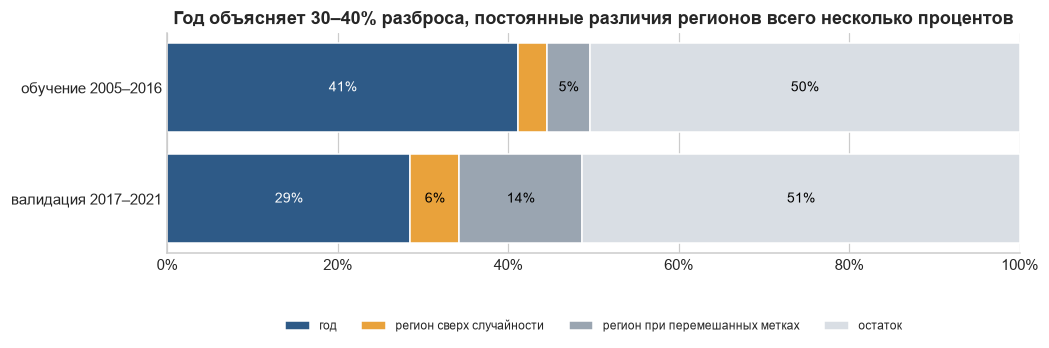

In [27]:
parts = ['год', 'регион сверх случайности', 'регион при перемешанных метках', 'остаток']
parts_colors = [color_main, color_second, color_grey, '#D9DEE4']

fig, ax = plt.subplots(figsize=(10, 2.6))
for j in range(len(var_shares.columns)):
    left = 0
    for k in range(len(parts)):
        w = var_shares[var_shares.columns[j]].loc[parts[k]]
        if j == 0:
            ax.barh(j, w, left=left, color=parts_colors[k], edgecolor='white', label=parts[k])
        else:
            ax.barh(j, w, left=left, color=parts_colors[k], edgecolor='white')
        if w > 0.04:
            if k == 0:
                text_color = 'white'
            else:
                text_color = 'black'
            ax.text(left + w / 2, j, f'{w:.0%}', ha='center', va='center', fontsize=9, color=text_color)
        left += w
ax.set_yticks(range(len(var_shares.columns)))
ax.set_yticklabels(var_shares.columns)
ax.set_xlim(0, 1)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1))
ax.set_title('Год объясняет 30–40% разброса, постоянные различия регионов всего несколько процентов')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.25), ncol=4, fontsize=8, frameon=False)
plt.show()

In [28]:
# держится ли среднее отклонение региона от своего года между обучением и валидацией
def region_dev(years):
    x = grp_sample[grp_sample['year'].between(*years)].dropna(subset=['g'])
    dev = x['g'] - x.groupby('year')['g'].transform('mean')
    return dev.groupby(x['region_id']).mean()


region_devs = pd.DataFrame({'обучение': region_dev(train_years), 'валидация': region_dev(val_years)}).dropna()
print(f'Регионов: {region_devs.shape[0]}', f'Корреляция обучение-валидация: {round(region_devs.corr().iloc[0, 1], 2)}', sep='\n')

Регионов: 85
Корреляция обучение-валидация: 0.26


In [29]:
# коррелирует ли отклонение региона от медианы года с прошлогодним значением
grp_lag = grp_sample[grp_sample['year'].between(train_years[0] - 1, val_years[1])].sort_values(['region_id', 'year']).copy()
grp_lag['dev'] = grp_lag['g'] - grp_lag.groupby('year')['g'].transform('median')
grp_lag['dev_lag'] = grp_lag.groupby('region_id')['dev'].shift(1)
grp_lag['g_lag'] = grp_lag.groupby('region_id')['g'].shift(1)

persistence = pd.DataFrame(columns=['corr(g, g_{t-1})', 'corr(откл., откл._{t-1})'])
for years, label in periods[:2]:
    x = grp_lag[grp_lag['year'].between(*years)].dropna(subset=['dev', 'dev_lag'])
    persistence.loc[label] = [x['g'].corr(x['g_lag']), x['dev'].corr(x['dev_lag'])]
persistence.index.name = 'период'
persistence = persistence.astype(float)
persistence

,"corr(g, g_{t-1})","corr(откл., откл._{t-1})"
период,,
обучение,0.21,0.14
валидация,-0.04,0.16


Год объясняет 41% разброса роста ВРП на обучении и 29% на валидации. Это главная составляющая роста ВРП.

Постоянные различия между регионами дают сырыми 8% и 20%, но большую часть этого даёт случайность: при перемешанных метках получается 5% и 14%. Сверх случайности остаётся около 3% на обучении и 6% на валидации. Эффект маленький, но значимый.

Различия регионов к тому же плохо держатся во времени. Корреляция среднего отклонения региона на обучении и на валидации всего 0,26. Вывод: эффекты регионов не выбрасывать, но сжимать к нулю с помощью случайных эффектов или l2-регуляризации и переоценивать на расширяющемся окне.

Остаток, около половины разброса, приходится на отклонения конкретного региона в конкретном году. Они почти не переносятся на следующий год: корреляция с прошлогодним отклонением 0,14–0,16. Годовую компоненту за год t-1 даёт опубликованный ВВП за год t-1, но при nowcasting года t её саму надо оценивать по квартальному ВВП и национальным месячным рядам. Отклонение региона от общего роста по его прошлому не предсказать, его можно взять только из региональных данных текущего года.

### 2.4. Карта «регион x год»

Цвет показывает отклонение роста региона от медианы своего года. Регионы упорядочены по федеральным округам, годы с 2005 по 2024.

In [30]:
grp_map = grp_sample[grp_sample['year'].between(2005, 2024)].copy()
grp_map['dev'] = grp_map['g'] - grp_map.groupby('year')['g'].transform('median')

regions_order = sample_regions.sort_values(['fd', 'name_short'])
heatmap_data = grp_map.pivot(index='region_id', columns='year', values='dev').reindex(regions_order['region_id'])
heatmap_data.index = [region_names[r][:28] for r in heatmap_data.index]

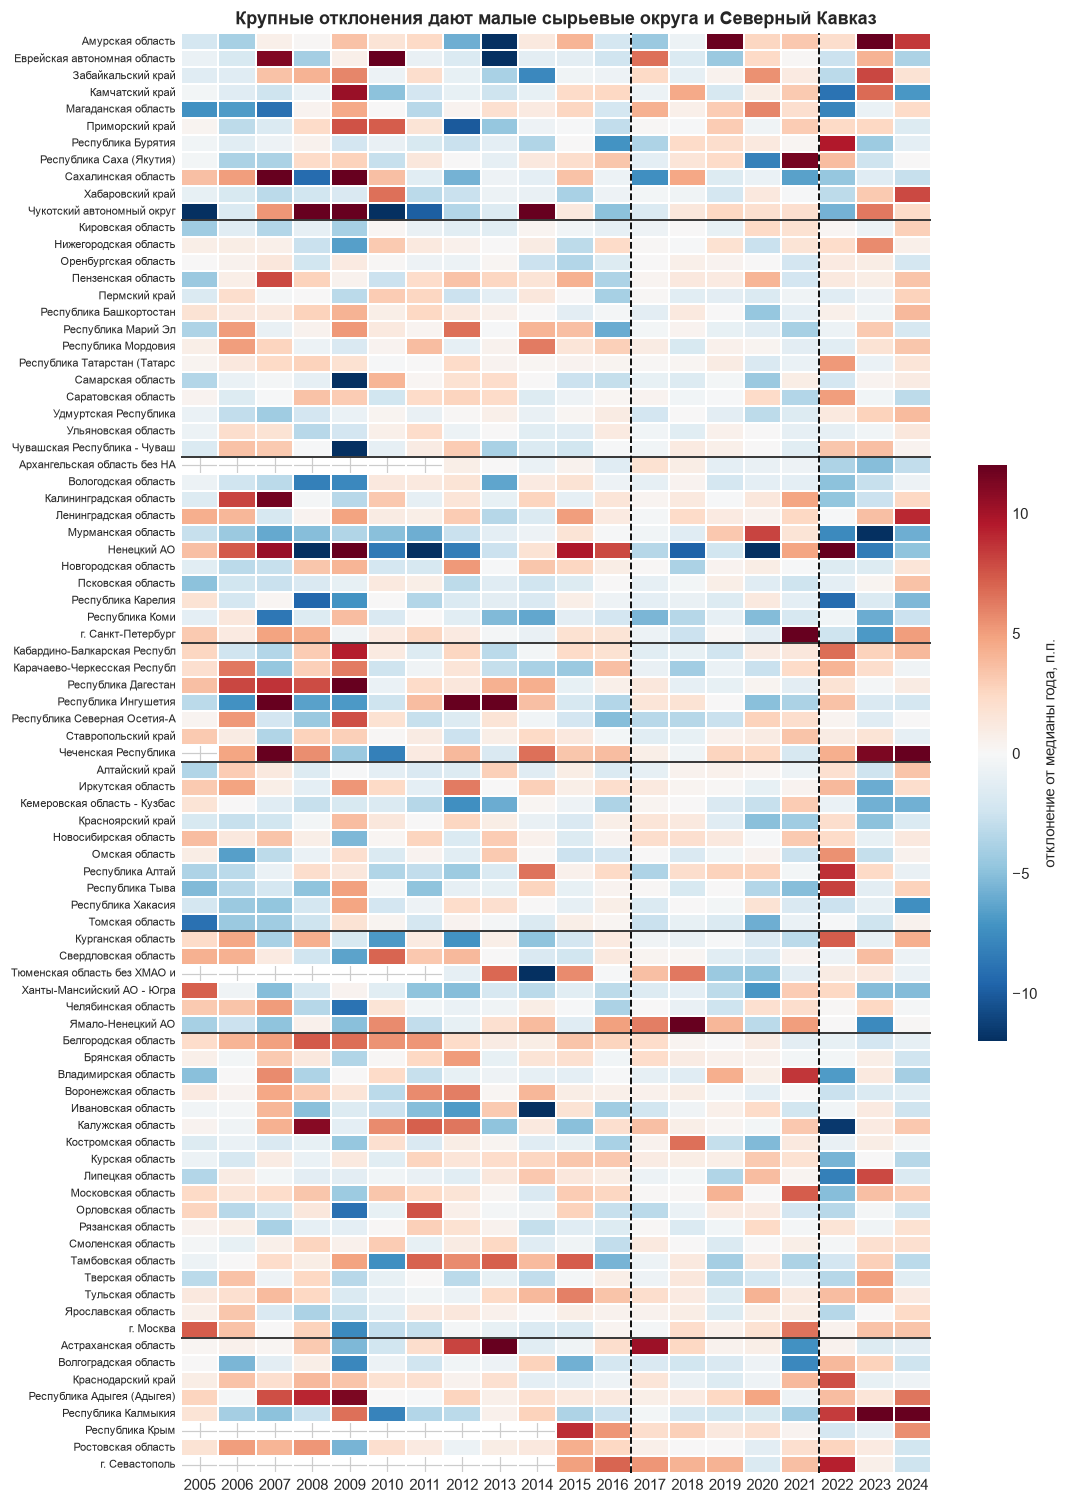

In [31]:
fig, ax = plt.subplots(figsize=(11, 17))
sns.heatmap(heatmap_data, cmap='RdBu_r', center=0, vmin=-12, vmax=12, ax=ax,
            cbar_kws={'label': 'отклонение от медианы года, п.п.', 'shrink': 0.4}, linewidths=0.2, linecolor='white')
fd_sorted = list(regions_order['fd'])
for i in range(1, len(fd_sorted)):
    if fd_sorted[i] != fd_sorted[i - 1]:
        ax.axhline(i, color='black', lw=1)
ax.axvline(train_years[1] - 2004, color='black', lw=1.2, ls='--')
ax.axvline(val_years[1] - 2004, color='black', lw=1.2, ls='--')
ax.set_xlabel('')
ax.set_ylabel('')
ax.tick_params(axis='y', labelsize=7)
ax.set_title('Крупные отклонения дают малые сырьевые округа и Северный Кавказ')
plt.show()

In [32]:
grp_vol = grp_sample[grp_sample['year'].between(train_years[0], val_years[1])].copy()
grp_vol['dev'] = grp_vol['g'] - grp_vol.groupby('year')['g'].transform('median')
volatility = grp_vol.groupby('name')['dev'].agg(['std', 'mean', 'count']).sort_values('std', ascending=False)

print('Самые волатильные регионы (std отклонения от медианы года, 2005–2021):')
display(volatility.head(12))
print('Самые стабильные:')
volatility.tail(6)

Самые волатильные регионы (std отклонения от медианы года, 2005–2021):


,std,mean,count
name,,,
Ненецкий АО,11.68,-0.60,17
Чукотский автономный округ,10.34,-0.36,17
Тюменская область без ХМАО и ЯНАО,7.54,-0.77,10
Сахалинская область,7.36,1.14,17
Республика Ингушетия,7.32,0.71,17
Еврейская автономная область,6.92,-0.39,17
Чеченская Республика,5.74,2.25,16
Астраханская область,5.27,1.64,17
Амурская область,5.23,-0.04,17


Самые стабильные:


,std,mean,count
name,,,
Псковская область,1.58,-1.41,17
Ульяновская область,1.53,-0.25,17
Удмуртская Республика,1.47,-1.11,17
Оренбургская область,1.41,-0.54,17
Республика Татарстан (Татарстан),1.18,0.64,17
Архангельская область без НАО,1.07,-0.10,10


Самые волатильные единицы: Ненецкий АО (стандартное отклонение от медианы года 11,7 п.п.), Чукотка (10,3), Тюменская область (7,5), Сахалин (7,4), Ингушетия (7,3), Еврейская АО (6,9). Самые ровные: Архангельская область (1,1), Татарстан (1,2), Удмуртия (1,5).

### 2.5. Наивные бенчмарки на валидации

Перед моделями полезно знать, какую ошибку дают самые простые правила, можно проанализировать ориентир для шкалы RMSE. Считаю только на валидации 2017–2021.

Рост ВРП каждого региона равен:
- «ВВП»: росту ВВП России за год.
- «Прошлый год»: рост региона как в t−1.
- «Среднее региона»: средний рост региона на обучающем окне.
- «ВВП + сдвиг региона»: ВВП плюс среднее отклонение региона от ВВП на обучении.

In [33]:
grp_val = grp_sample[grp_sample['year'].between(*val_years)].copy()
grp_val['gdp'] = grp_val['year'].map(gdp_growth)
grp_train = grp_sample[grp_sample['year'].between(*train_years)].copy()
grp_train['gdp'] = grp_train['year'].map(gdp_growth)

region_mean = grp_train.groupby('region_id')['g'].mean()
region_shift = (grp_train['g'] - grp_train['gdp']).groupby(grp_train['region_id']).mean()

g_by_region_year = grp_sample.set_index(['region_id', 'year'])['g']
lags = []
for r, y in zip(grp_val['region_id'], grp_val['year']):
    lags.append(g_by_region_year.get((r, y - 1), np.nan))
grp_val['lag'] = lags

In [34]:
benchmarks = {'ВВП': grp_val['gdp'],
              'прошлый год': grp_val['lag'],
              'среднее региона (обучение)': grp_val['region_id'].map(region_mean),
              'ВВП + сдвиг региона': grp_val['gdp'] + grp_val['region_id'].map(region_shift)}


def rmse(errors):
    return float(np.sqrt(np.nanmean(errors ** 2)))


bench = pd.DataFrame(columns=['RMSE, п.п.', 'MAE, п.п.'])
bench_years = pd.DataFrame()
for name in benchmarks:
    errors = grp_val['g'] - benchmarks[name]
    bench.loc[name] = [rmse(errors), float(np.nanmean(np.abs(errors)))]
    bench_years[name] = errors.groupby(grp_val['year']).apply(rmse)
bench = bench.astype(float)
bench.sort_values('RMSE, п.п.')

,"RMSE, п.п.","MAE, п.п."
ВВП,3.04,2.18
ВВП + сдвиг региона,3.42,2.49
среднее региона (обучение),3.92,2.94
прошлый год,4.71,3.29


In [35]:
bench_years.round(2)

,ВВП,прошлый год,среднее региона (обучение),ВВП + сдвиг региона
year,,,,
2017,2.48,3.44,2.96,2.62
2018,2.63,2.94,3.08,3.10
2019,2.39,3.29,3.06,2.96
2020,3.52,4.69,5.74,3.71
2021,3.90,7.58,4.01,4.44


На валидации правило «рост региона равен росту ВВП» даёт RMSE 3,04 п.п. и оказывается лучшим из четырёх. Добавка постоянного сдвига региона ухудшает его до 3,42: сдвиги, оценённые на 2005–2016 годах, не держатся в 2017–2021. Прошлогодний рост региона даёт 4,71.

Получается планка: для дат оценки backcasting, когда ВВП уже известен, модель должна давать RMSE заметно ниже 3 п.п. на валидации. Для дат оценки nowcasting ВВП ещё нет а год t, там ориентиром будет квартальный ВВП и прогнозы. В 2020–2021 годах ошибка бенчмарка ВВП растёт до 3,5–3,9 п.п.

## 3. Признаки

Предварительное обучающее окно дизайна 2005–2016. Многие месячные ряды в ОКВЭД2 начинаются с 2015–2019 годов, кредиты Банка России с 2019 года. Ниже доля заполненных ячеек «регион x месяц» по каждому региональному месячному признаку и году.

In [36]:
monthly = monthly_long[monthly_long['region_id'].isin(sample_ids)].copy()
monthly['year'] = monthly['year'].astype(int)
monthly_catalog = catalog[catalog['table'] == 'regional_monthly'][['feature', 'group', 'freq_source']].set_index('feature')

In [37]:
# доля заполненных ячеек «регион x месяц» по признаку и году
months_in_year = {'M': 12, 'Q': 4}
counts = monthly.groupby(['feature', 'year'])['value'].count().unstack(fill_value=0)
expected = monthly_catalog['freq_source'].map(months_in_year).reindex(counts.index) * len(sample_ids)
coverage = counts.div(expected, axis=0).clip(upper=1).reindex(columns=range(2000, 2027), fill_value=0)

# сортируем признаки по группе и году появления
coverage_order = pd.DataFrame({'group': monthly_catalog['group'].reindex(coverage.index),
                               'first_year': (coverage > 0.5).idxmax(axis=1),
                               'name': coverage.index}, index=coverage.index)
coverage_order = coverage_order.sort_values(['group', 'first_year', 'name'])
coverage = coverage.loc[coverage_order.index]

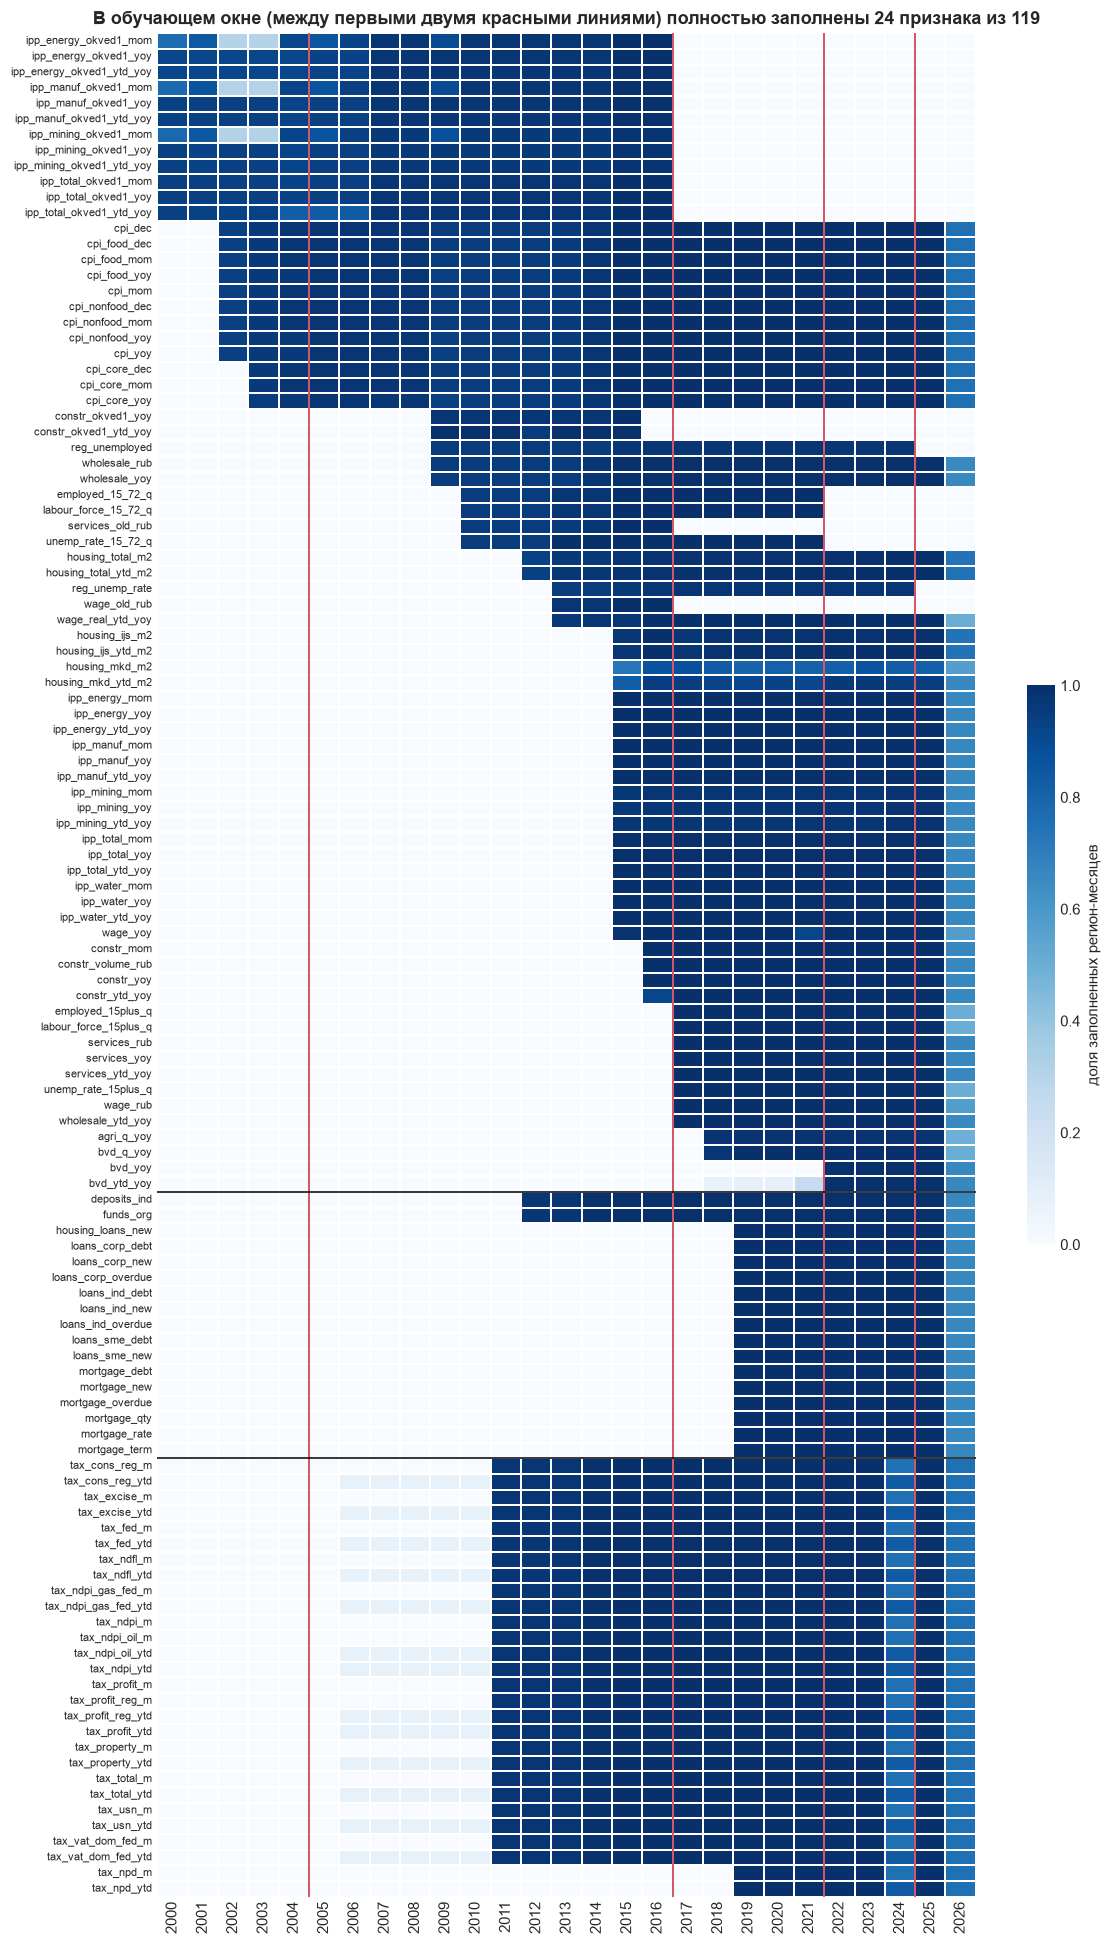

In [38]:
fig, ax = plt.subplots(figsize=(12, 22))
sns.heatmap(coverage, cmap='Blues', vmin=0, vmax=1, ax=ax, cbar_kws={'label': 'доля заполненных регион-месяцев', 'shrink': 0.3},
            linewidths=0.1, linecolor='white')
for x in [train_years[0] - 2000, train_years[1] + 1 - 2000, val_years[1] + 1 - 2000, test_years[1] + 1 - 2000]:
    ax.axvline(x, color=color_accent, lw=1.2)
groups_sorted = list(coverage_order['group'])
for i in range(1, len(groups_sorted)):
    if groups_sorted[i] != groups_sorted[i - 1]:
        ax.axhline(i, color='black', lw=1)
ax.tick_params(axis='y', labelsize=7)
ax.set_ylabel('')
ax.set_xlabel('')
ax.set_title('В обучающем окне (между первыми двумя красными линиями) полностью заполнены 24 признака из 119')
plt.show()

In [39]:
availability = pd.DataFrame()
for years, label in periods:
    availability[label] = coverage.loc[:, years[0]:years[1]].mean(axis=1)
availability['group'] = monthly_catalog['group'].reindex(availability.index)

summary = pd.DataFrame(index=['>=90% ячеек', 'частично', '<=10% ячеек'])
for years, label in periods:
    full = (availability[label] >= 0.9).sum()
    part = ((availability[label] > 0.1) & (availability[label] < 0.9)).sum()
    empty = (availability[label] <= 0.1).sum()
    summary[label] = [full, part, empty]
print('Региональных месячных признаков всего:', availability.shape[0])
summary

Региональных месячных признаков всего: 119


,обучение,валидация,тест
>=90% ячеек,24,81,99
частично,62,20,1
<=10% ячеек,33,18,19


In [40]:
# распределение признаков с >=90% ячеек по группе признаков
full_by_group = (availability[['обучение', 'валидация', 'тест']] >= 0.9).groupby(availability['group']).sum()
full_by_group['всего'] = availability.groupby('group').size()
full_by_group

,обучение,валидация,тест,всего
group,,,,
1. Официальная месячная статистика,24,53,54,74
3. Финансы и кредит,0,2,17,17
4. Бюджет и налоги,0,26,28,28


Это главная проблема датасета для текущего дизайна. В обучающем окне 2005–2016 годов на 90% и больше заполнены только 24 из 119 региональных месячных признаков: ИПП и ИПЦ. Кредитов нет совсем (0 из 17, ряды ЦБ начинаются в 2019 году), налоги помесячно есть только с 2011 года (0 из 28 заполнены на 90% за всё окно). Торговля и строительство начинаются с 2009 года, ввод жилья с 2012-го. На валидации полных признаков уже 81, на тесте 99.

Выходит, что модель, обученная на 2005–2016 годах, видит только промышленность и цены, а на тесте ей доступно в 4 раза больше рядов. Вариантов три: 
- сдвинуть начало обучения к 2011–2012 годам (меньше лет, но полный набор налогов, строительства и торговли); 
- брать модели, которые сами работают с пропусками;
- делать две версии, длинную на ИПП и ИПЦ и короткую на всех рядах. 

!!! Это надо обсудить.

### 3.1. Пробелы по регионам

Матрица «регион x признак» из `coverage_matrix_regional_monthly.csv` с числом доступных месяцев. Нормирую на максимум по признаку и показываю регионы, у которых средняя заполненность ниже остальных.

In [41]:
coverage_matrix = pd.read_csv(path_processed / 'coverage_matrix_regional_monthly.csv').set_index('region_id')
coverage_matrix = coverage_matrix[coverage_matrix.index.isin(sample_ids)]
coverage_matrix_norm = coverage_matrix / coverage_matrix.max()

region_fill = coverage_matrix_norm.mean(axis=1).sort_values()
low_fill = region_fill.head(12)
gaps = (coverage_matrix_norm < 0.8).sum(axis=1).reindex(low_fill.index)

low_regions = pd.DataFrame({'средняя заполненность': low_fill.values, 'признаков с <80% месяцев': gaps.values},
                           index=[region_names[r] for r in low_fill.index])
low_regions.index.name = 'регион'
low_regions

,средняя заполненность,признаков с <80% месяцев
регион,,
г. Севастополь,0.74,67
Республика Крым,0.76,64
Архангельская область без НАО,0.90,32
Тюменская область без ХМАО и ЯНАО,0.90,32
Чеченская Республика,0.94,13
Чукотский автономный округ,0.96,9
г. Москва,0.96,6
Республика Ингушетия,0.98,4
Магаданская область,0.99,2


In [42]:
# месяцы, которых нет сразу у всех регионов внутри периода, где признак публикуется
holes = pd.DataFrame(columns=['пропущено месяцев'])
for f, d in monthly.groupby('feature'):
    if monthly_catalog.loc[f, 'freq_source'] == 'M':
        months = range(1, 13)
    else:
        months = (3, 6, 9, 12)
    years_count = d.groupby('year')['value'].count()
    y0 = years_count[years_count > 0].index.min()
    y1 = years_count[years_count > 0].index.max()
    d_notna = d.dropna(subset=['value'])
    have = set(zip(d_notna['year'], d_notna['month']))
    miss = []
    for y in range(y0, y1 + 1):
        for m in months:
            if (y, m) not in have and min(have) < (y, m) < max(have):
                miss.append((y, m))
    if len(miss) > 0:
        holes.loc[f] = len(miss)
holes.index.name = 'признак'
holes = holes.astype(int)
holes = holes.sort_values('пропущено месяцев', ascending=False)
print('Признаков со сплошными дырами:', holes.shape[0])
holes.head(25)

Признаков со сплошными дырами: 33


,пропущено месяцев
признак,
tax_ndpi_oil_ytd,46
tax_ndpi_gas_fed_ytd,46
tax_vat_dom_fed_ytd,46
tax_usn_ytd,46
tax_total_ytd,46
tax_cons_reg_ytd,46
tax_property_ytd,46
tax_excise_ytd,46
tax_profit_ytd,46


По регионам меньше всего данных у Севастополя и Крыма (средняя заполненность 74–76%, их ряды начинаются в 2014–2015 годах) и у двух областей (Тюменская и Архангельская области, 90%, у них 32 признака заполнены меньше чем на 80%). Остальные регионы заполнены на 94% и выше.

Сплошные дыры, месяцы, которых нет ни у одного региона, нашлись в 33 признаках.

## 4. Качество признаков

### 4.1. Нули и выбросы в индексах

Индексы (`*_yoy`, `*_mom`, `*_ytd_yoy`, `*_dec`) в процентах к прошлому году, при этом прошлый год = 100. Считаю на обучающем окне по регионам количество нулей, долю значений вне диапазона [50, 200] и экстремумы.

In [43]:
index_features = []
for f in monthly_catalog.index:
    if f.endswith('_yoy') or f.endswith('_mom') or f.endswith('_dec'):
        index_features.append(f)

monthly_index = monthly[monthly['feature'].isin(index_features)]
monthly_index_train = monthly_index[monthly_index['year'].between(*train_years)]

In [44]:
quality = pd.DataFrame(columns=['n', 'нулей', 'out_50_200', 'p01', 'p99', 'max'])
for f, d in monthly_index_train.groupby('feature'):
    s = d['value']
    positive = s[s > 0]
    out_share = ((s != 0) & ((s < 50) | (s > 200))).mean() * 100
    quality.loc[f] = [s.count(), (s == 0).sum(), out_share, positive.quantile(0.01), positive.quantile(0.99), s.max()]
quality.index.name = 'feature'
quality = quality.astype(float)
quality = quality[quality['n'] > 0].sort_values('out_50_200', ascending=False)
quality.head(15)

,n,нулей,out_50_200,p01,p99,max
feature,,,,,,
constr_mom,"1,020.00",0.00,12.25,12.94,289.36,656.00
constr_yoy,"1,020.00",0.00,7.84,28.89,273.67,522.60
constr_okved1_yoy,"6,996.00",78.00,7.73,28.62,297.96,"2,583.60"
ipp_mining_okved1_yoy,"11,793.00",28.00,6.25,35.10,359.76,"7,961.80"
ipp_mining_okved1_mom,"11,631.00",17.00,5.15,34.00,278.03,"9,400.90"
constr_okved1_ytd_yoy,"7,084.00",212.00,4.07,42.04,248.46,"1,020.50"
ipp_mining_yoy,"1,980.00",0.00,3.79,45.22,289.36,"1,449.70"
ipp_mining_mom,"1,985.00",0.00,3.78,39.48,230.01,462.90
ipp_mining_okved1_ytd_yoy,"11,793.00",11.00,3.77,42.98,281.87,"5,584.50"


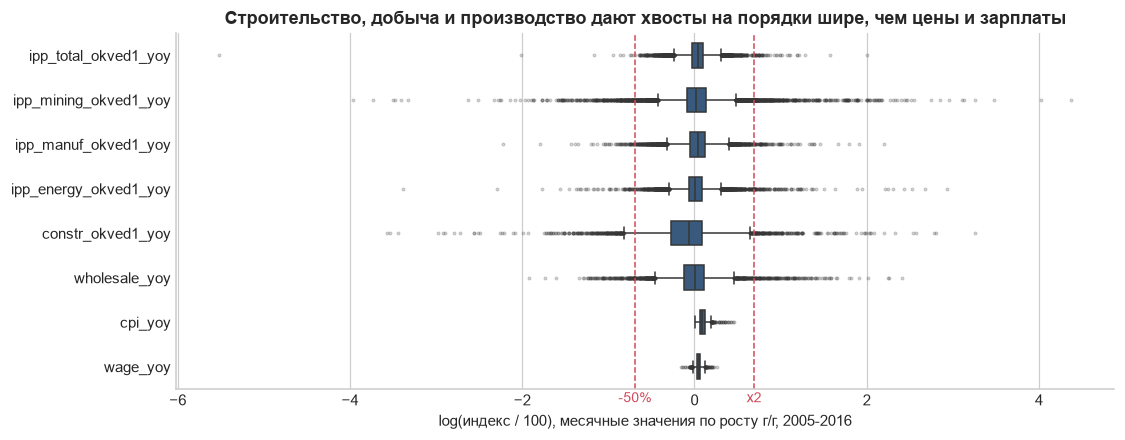

In [45]:
main_index = ['ipp_total_okved1_yoy', 'ipp_mining_okved1_yoy', 'ipp_manuf_okved1_yoy', 'ipp_energy_okved1_yoy',
              'constr_okved1_yoy', 'wholesale_yoy', 'cpi_yoy', 'wage_yoy']
log_index = monthly_index_train[monthly_index_train['feature'].isin(main_index) & (monthly_index_train['value'] > 0)].copy()
log_index['log_ratio'] = np.log(log_index['value'] / 100)

fig, ax = plt.subplots(figsize=(11, 4.2))
sns.boxplot(data=log_index, y='feature', x='log_ratio', order=main_index, ax=ax, color=color_main, fliersize=1.5, width=0.55,
            flierprops={'alpha': 0.3})
ax.axvline(np.log(0.5), color=color_accent, ls='--', lw=1)
ax.text(np.log(0.5), 7.8, '-50%', color=color_accent, ha='center', fontsize=9)
ax.axvline(np.log(2), color=color_accent, ls='--', lw=1)
ax.text(np.log(2), 7.8, 'x2', color=color_accent, ha='center', fontsize=9)
ax.set_xlabel('log(индекс / 100), месячные значения по росту г/г, 2005-2016')
ax.set_ylabel('')
ax.set_title('Строительство, добыча и производство дают хвосты на порядки шире, чем цены и зарплаты')
plt.show()

В строительстве и добыче от 3 до 12% месячных значений лежат вне диапазона [50, 200], то есть показывают падение или рост больше чем вдвое к прошлому году. Цены и зарплаты лежат в узком коридоре. Нулей в строительстве с начала года 212, при этом они означают не нулевой выпуск, а пропуски.

Вывод: нули в индексах заменить на пропуски, индексы перевести в логарифмическую шкалу log(индекс/100).

### 4.2. Стык ОКВЭД-2007 и ОКВЭД2 в ИПП

ИПП публикуется в обеих классификациях за 2015–2016 годы. Можно проверить, допустимо ли склеивать ряды без поправок.

In [46]:
okved_pairs = [('ipp_total_yoy', 'ipp_total_okved1_yoy'), ('ipp_mining_yoy', 'ipp_mining_okved1_yoy'),
               ('ipp_manuf_yoy', 'ipp_manuf_okved1_yoy'), ('ipp_energy_yoy', 'ipp_energy_okved1_yoy')]
overlap = monthly[monthly['year'].between(2015, 2016)].pivot_table(index=['region_id', 'year', 'month'], columns='feature', values='value')

splice = pd.DataFrame(columns=['n', 'corr', 'средняя разница, п.п.', 'медиана |разницы|', 'доля |разницы| > 5 п.п., %'])
for new, old in okved_pairs:
    x = overlap[[new, old]].replace(0, np.nan).dropna()
    x = x[(x[new].between(20, 500)) & (x[old].between(20, 500))]
    diff = x[new] - x[old]
    splice.loc[new.replace('_yoy', '')] = [x.shape[0], x[new].corr(x[old]), diff.mean(), diff.abs().median(), (diff.abs() > 5).mean() * 100]
splice.index.name = 'ряд'
splice = splice.astype(float)
splice

,n,corr,"средняя разница, п.п.",медиана |разницы|,"доля |разницы| > 5 п.п., %"
ряд,,,,,
ipp_total,"2,040.00",0.56,1.41,4.50,46.13
ipp_mining,"1,964.00",0.67,2.49,4.70,47.66
ipp_manuf,"2,040.00",0.60,2.52,6.50,57.84
ipp_energy,"2,027.00",0.54,-0.08,3.00,33.70


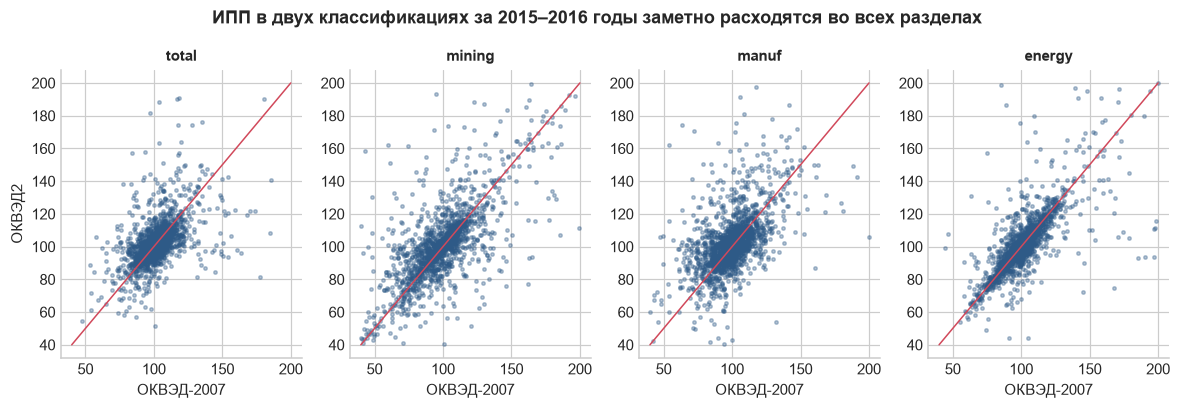

In [47]:
fig, ax = plt.subplots(1, 4, figsize=(13, 3.4))
for i in range(len(okved_pairs)):
    new, old = okved_pairs[i]
    x = overlap[[new, old]].replace(0, np.nan).dropna()
    x = x[(x[new].between(40, 200)) & (x[old].between(40, 200))]
    ax[i].scatter(x[old], x[new], s=5, alpha=0.35, color=color_main)
    ax[i].plot([40, 200], [40, 200], color=color_accent, lw=1)
    ax[i].set_title(new.replace('ipp_', '').replace('_yoy', ''), fontsize=10)
    ax[i].set_xlabel('ОКВЭД-2007')
ax[0].set_ylabel('ОКВЭД2')
plt.suptitle('ИПП в двух классификациях за 2015–2016 годы заметно расходятся во всех разделах', fontweight='bold', y=1.04)
plt.show()

In [48]:
# тот же стык на уровне РФ и на годовых значениях
rf_ipp_overlap = monthly_long[(monthly_long['region_id'] == 'rossiyskaya_federatsiya') & monthly_long['year'].isin([2015, 2016]) & (monthly_long['month'] == 12)]
rf_ipp_overlap = rf_ipp_overlap.pivot_table(index='year', columns='feature', values='value')[['ipp_total_okved1_ytd_yoy', 'ipp_total_ytd_yoy']]
print('ИПП РФ за год, %:')
rf_ipp_overlap.rename(columns={'ipp_total_okved1_ytd_yoy': 'ОКВЭД-2007', 'ipp_total_ytd_yoy': 'ОКВЭД2'})

ИПП РФ за год, %:


feature,ОКВЭД-2007,ОКВЭД2
year,,
2015,96.60,100.20
2016,101.10,101.80


In [49]:
annual_overlap = monthly[(monthly['month'] == 12) & monthly['year'].isin([2015, 2016]) & monthly['feature'].isin(['ipp_total_ytd_yoy', 'ipp_total_okved1_ytd_yoy'])]
annual_overlap = annual_overlap.pivot_table(index=['region_id', 'year'], columns='feature', values='value').dropna()
annual_diff = annual_overlap['ipp_total_ytd_yoy'] - annual_overlap['ipp_total_okved1_ytd_yoy']

print(f'Корреляция годового ИПП регионов: {round(annual_overlap.corr().iloc[0, 1], 2)}',
      f'Медиана |разницы|: {round(annual_diff.abs().median(), 1)} п.п.',
      f'Доля пар регион-год с |разницей| > 5 п.п.: {round((annual_diff.abs() > 5).mean() * 100)}%', sep='\n')

Корреляция годового ИПП регионов: 0.57
Медиана |разницы|: 1.6 п.п.
Доля пар регион-год с |разницей| > 5 п.п.: 17%


Ряды в двух классификациях не взаимозаменяемы. Помесячно корреляция 0,54–0,67, а у больше, чем трети пар «регион-месяц» разница больше 5 п.п. На годовых значениях расхождение меньше (корреляция 0,57, медиана разницы 1,6 п.п., больше 5 п.п. у 17% пар), но и по РФ в целом 2015 год выглядит по-разному: 96,6% в ОКВЭД-2007 и 100,2% в ОКВЭД2.

В разделе 5 я беру ОКВЭД-2007 до 2016 года и ОКВЭД2 с 2017-го для признаков и цели одновременно. 

Вывод: стоит добавить индикатор режима классификации.

### 4.3. Сезонность признаков

Помесячные признаки возможно имеют сильную сезонность. На графике - медианная доля каждого месяца в годовой сумме по регионам за 2017–2021 годы.

In [50]:
flows = {'tax_total_m': 'налоги ФНС', 'housing_total_m2': 'ввод жилья', 'constr_volume_rub': 'строительство, руб.',
         'wholesale_rub': 'опт, руб.', 'services_rub': 'платные услуги'}
monthly_flows = monthly[monthly['feature'].isin(flows) & monthly['year'].between(2017, 2021)].copy()
monthly_flows['share'] = monthly_flows['value'] / monthly_flows.groupby(['feature', 'region_id', 'year'])['value'].transform('sum') * 100
season_profile = monthly_flows.groupby(['feature', 'month'])['share'].median().unstack(0).rename(columns=flows)

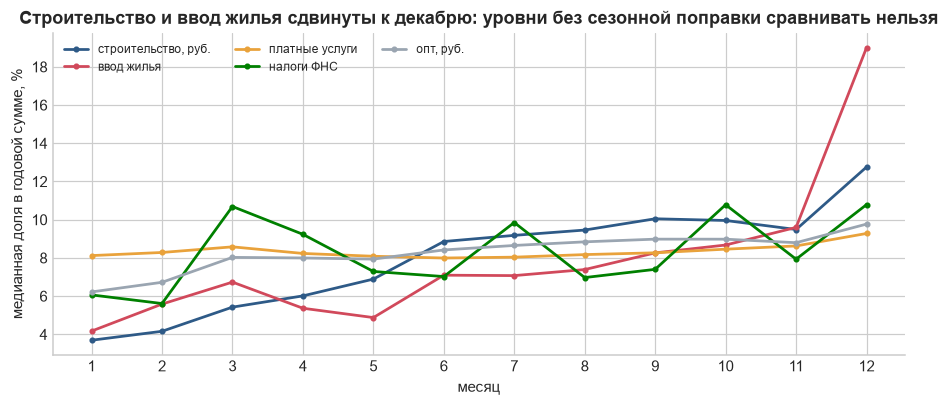

In [51]:
line_colors = [color_main, color_accent, color_second, 'green', color_grey]

fig, ax = plt.subplots(figsize=(10, 3.8))
for i in range(len(season_profile.columns)):
    c = season_profile.columns[i]
    ax.plot(season_profile.index, season_profile[c], marker='o', ms=3, lw=1.8, color=line_colors[i], label=c)
ax.set_xticks(range(1, 13))
ax.set_xlabel('месяц')
ax.set_ylabel('медианная доля в годовой сумме, %')
ax.set_title('Строительство и ввод жилья сдвинуты к декабрю: уровни без сезонной поправки сравнивать нельзя')
ax.legend(fontsize=8, ncol=3)
plt.show()

In [52]:
season_profile.round(1).T

month,1,2,3,4,5,6,7,8,9,10,11,12
feature,,,,,,,,,,,,
"строительство, руб.",3.70,4.20,5.40,6.00,6.90,8.90,9.20,9.50,10.00,10.00,9.50,12.80
ввод жилья,4.20,5.60,6.70,5.40,4.90,7.10,7.10,7.40,8.30,8.70,9.60,19.00
платные услуги,8.10,8.30,8.60,8.20,8.10,8.00,8.00,8.20,8.30,8.50,8.60,9.30
налоги ФНС,6.10,5.60,10.70,9.20,7.30,7.00,9.90,7.00,7.40,10.80,7.90,10.80
"опт, руб.",6.20,6.70,8.00,8.00,7.90,8.40,8.70,8.80,9.00,9.00,8.80,9.80


На декабрь приходится 12,8% годового объёма строительства (в январе 3,7%) и 19% годового ввода жилья. Налоги идут волнами по срокам уплаты: пики в марте, июле, октябре и декабре (около 10–11% против 6–8% в соседних месяцах). Платные услуги и опт почти равномерны.

Индексы к прошлому месяцу без сезонной поправки для модели не годятся.
Для годовой цели они не добавляют информации, так как двенадцать перемноженных месячных индексов дают тот же годовой рост, что уже есть в индексе с начала года.

Поэтому беру индексы к прошлому году и с начала года. Индексы к прошлому месяцу можно взять только после сезонной поправки, а на коротких региональных рядах её не сделать надёжно.

## 5. Связь годовых агрегатов признаков с ростом ВРП

Цель годовая, а признаки месячные, поэтому свожу каждый месячный ряд к году так, как он будет доступен к концу года t:

- индексы «с начала года» беру за декабрь, это и есть годовой рост;
- где ряда с начала года нет (например, опт до 2017 года), беру среднее месячных г/г;
- значения рядов с единицей измерения в рублях суммирую за год и дефлирую региональным ИПЦ декабрь к декабрю;
- ряды ОКВЭД-2007 использую до 2016 года, ОКВЭД2 с 2017 года (для строительства граница 2015/2016, как в источнике);

Признаки с первым годом после 2016 в обучении не участвуют, их связь видна только на валидации.

In [53]:
monthly_wide = monthly.pivot_table(index=['region_id', 'year', 'month'], columns='feature', values='value').reset_index()
monthly_columns = [c for c in monthly_wide.columns if c not in ('region_id', 'year', 'month')]

# ноль в индексе или в нарастающем итоге означает пропуск в источнике
monthly_clean = monthly_wide.copy()
monthly_clean[monthly_columns] = monthly_clean[monthly_columns].replace(0, np.nan)
december = monthly_clean[monthly_clean['month'] == 12].set_index(['region_id', 'year'])

annual = annual_wide.copy()
annual['year'] = annual['year'].astype(int)
annual = annual[annual['region_id'].isin(sample_ids)].set_index(['region_id', 'year'])

In [54]:
def splice_december(new, old, last_old=2016):
    years = december.index.get_level_values('year')
    s_old = december[old].where(years <= last_old)
    s_new = december[new].where(years > last_old)
    return s_new.fillna(s_old)


def annual_mean(f):
    return monthly_clean.groupby(['region_id', 'year'])[f].mean()


def real_growth(column):
    s = december[column]
    return s / s.groupby('region_id').shift(1) / (december['cpi_dec'] / 100) * 100

In [55]:
features = pd.DataFrame(index=december.index)
features['ИПП'] = splice_december('ipp_total_ytd_yoy', 'ipp_total_okved1_ytd_yoy')
features['ИПП добыча'] = splice_december('ipp_mining_ytd_yoy', 'ipp_mining_okved1_ytd_yoy')
features['ИПП обработка'] = splice_december('ipp_manuf_ytd_yoy', 'ipp_manuf_okved1_ytd_yoy')
features['ИПП энергетика'] = splice_december('ipp_energy_ytd_yoy', 'ipp_energy_okved1_ytd_yoy')
features['строительство'] = splice_december('constr_ytd_yoy', 'constr_okved1_ytd_yoy', last_old=2015)
features['опт'] = december['wholesale_ytd_yoy'].fillna(annual_mean('wholesale_yoy').reindex(december.index))
features['платные услуги'] = december['services_ytd_yoy']
features['реальная зарплата'] = december['wage_real_ytd_yoy']
features['ИПЦ дек/дек'] = december['cpi_dec']
features['выпуск базовых видов'] = december['bvd_ytd_yoy']
housing = december['housing_total_ytd_m2']
features['ввод жилья'] = housing / housing.groupby('region_id').shift(1) * 100
features['налоги реал.'] = real_growth('tax_total_ytd')
features['НДФЛ реал.'] = real_growth('tax_ndfl_ytd')
features['сельское хоз.'] = annual['agri_y_yoy'].fillna(annual['agri_old_y_yoy']).replace(0, np.nan).reindex(features.index)
features['розница (год)'] = annual['retail_y_yoy'].replace(0, np.nan).reindex(features.index)
features['кредит ЮЛ реал.'] = real_growth('loans_corp_debt')

In [56]:
n_inf = int(np.isinf(features.values).sum())
features = features.replace([np.inf, -np.inf], np.nan)
features = features.reset_index()
features['ВВП'] = features['year'].map(gdp_growth) + 100
features = features.merge(grp_sample[['region_id', 'year', 'g']], on=['region_id', 'year'], how='left')

feature_names = [c for c in features.columns if c not in ('region_id', 'year', 'g')]
features[feature_names] = features[feature_names] - 100  # всё в приросте, п.п.

n_zero = int((monthly_wide[monthly_wide['month'] == 12][monthly_columns] == 0).sum().sum())
print(f'Нулей в декабрьских значениях заменено на пропуск: {n_zero}', f'Бесконечностей после деления заменено: {n_inf}', sep='\n')

Нулей в декабрьских значениях заменено на пропуск: 4377
Бесконечностей после деления заменено: 0


In [57]:
first_year_feature = pd.Series(dtype=float)
for f in feature_names:
    share = features[f].notna().groupby(features['year']).mean()
    first_year_feature[f] = share[share > 0.8].index.min()
print('Первый год, когда признак есть у >80% регионов:')
first_year_feature.astype(int).sort_values()

Первый год, когда признак есть у >80% регионов:


сельское хоз.           1999
ИПП                     2000
ИПП добыча              2000
ИПП обработка           2000
ИПП энергетика          2000
розница (год)           2000
ИПЦ дек/дек             2002
ВВП                     2002
налоги реал.            2007
НДФЛ реал.              2007
опт                     2009
строительство           2009
реальная зарплата       2013
ввод жилья              2013
платные услуги          2017
выпуск базовых видов    2018
кредит ЮЛ реал.         2020
dtype: int64

Корреляции c ВРП считаю двумя способами. Обычная корреляция по панели смешивает общий шок года и регионы внутри года. Для nowcasting региона важна вторая часть, поэтому рядом показываю корреляцию после вычитания среднего по году из цели и из признака (внутри года).

Рядом с обычной корреляцией (Пирсон) считаю ранговую внутри года (Спирмен): ранжирую регионы по признаку и по росту ВРП внутри каждого года. Если ранговая заметно ниже, связь держится на нескольких крайних значениях.

Проводим винзоризацию, чтобы исключить влияние экстремальных значений на расчет корреляции. Пороги 1-го и 99-го перцентилей каждого признака считаются на обучающем окне и применяются к валидации, то есть значения экстремальнее этих порогов удаляются из анализа корреляции. У трёх признаков (платные услуги, выпуск базовых видов, кредиты) истории в обучении нет. Для них пороги беру по первому году валидации, где признак есть у 60 и больше регионов, а сам этот год исключаю из корреляций.

In [58]:
# винзоризация: пороги 1-го и 99-го перцентилей обучающего окна
features_w = features.copy()
bounds = {}
threshold_year = {}  # признаки без истории в обучении
for f in feature_names:
    base = features_w[features_w['year'].between(*train_years)][f].dropna()
    if base.shape[0] < 100:
        counts_val = features_w[features_w['year'].between(*val_years)][['year', f]].dropna().groupby('year').size()
        threshold_year[f] = int(counts_val[counts_val >= 60].index.min())
        base = features_w[features_w['year'] == threshold_year[f]][f].dropna()
    bounds[f] = (base.quantile(0.01), base.quantile(0.99))
    features_w[f] = features_w[f].clip(*bounds[f])
print('Пороги по первому году валидации (этот год исключён из корреляций):', threshold_year)

Пороги по первому году валидации (этот год исключён из корреляций): {'платные услуги': 2017, 'выпуск базовых видов': 2018, 'кредит ЮЛ реал.': 2020}


In [59]:
def within_corr(df, f, method='pearson'):
    z = df[['year', f, 'g']].copy()
    if method == 'spearman':
        z[[f, 'g']] = z.groupby('year')[[f, 'g']].rank()
    w = z[[f, 'g']] - z.groupby('year')[[f, 'g']].transform('mean')
    if w[f].std() > 0:
        return w[f].corr(w['g'])
    else:
        return np.nan


def corr_table(df, years):
    x = df[df['year'].between(*years)]
    result = pd.DataFrame(columns=['r', 'r_pearson внутри года', 'r_spearman внутри года', 'n'])
    for f in feature_names:
        z = x[['year', f, 'g']].dropna()
        if f in threshold_year:
            z = z[z['year'] > threshold_year[f]]
        if z.shape[0] < 60 or z[f].std() == 0:
            result.loc[f] = [np.nan, np.nan, np.nan, z.shape[0]]
        else:
            result.loc[f] = [z[f].corr(z['g']), within_corr(z, f), within_corr(z, f, 'spearman'), z.shape[0]]
    return result.astype(float)

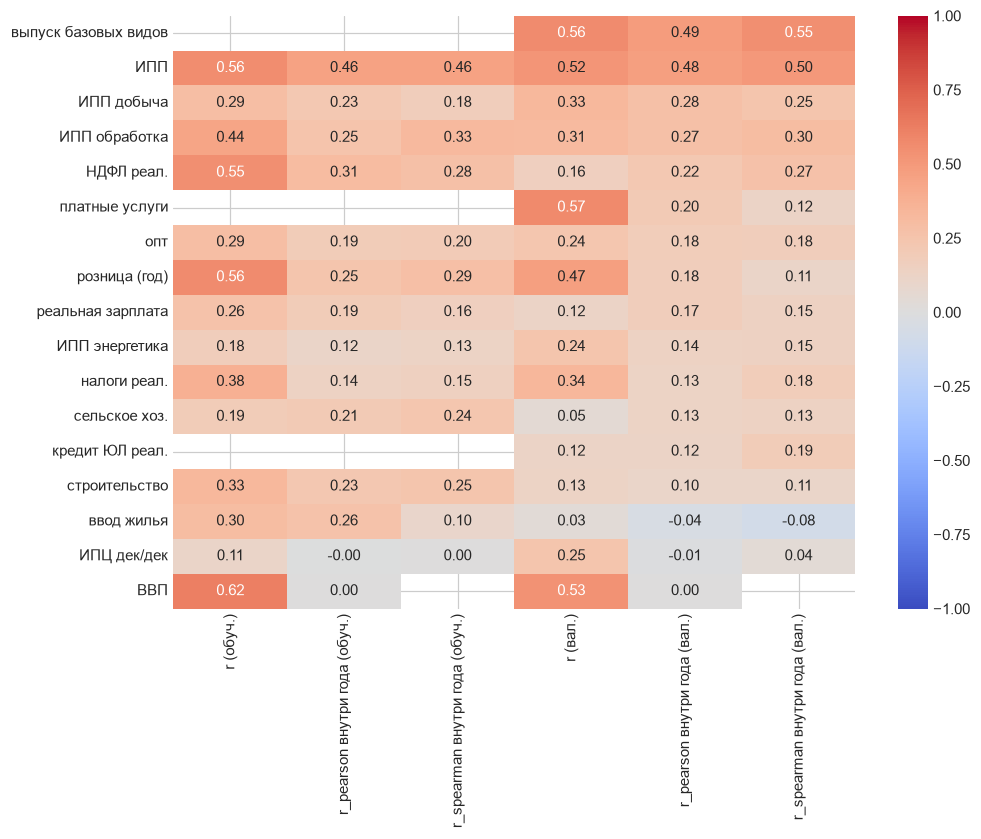

In [60]:
corr_features = corr_table(features_w, train_years).add_suffix(' (обуч.)').join(corr_table(features_w, val_years).add_suffix(' (вал.)'))
sort_order = corr_features['r_pearson внутри года (вал.)'].abs().sort_values(ascending=False).index
corr_features = corr_features.loc[sort_order]
r_columns = [c for c in corr_features.columns if not c.startswith('n')]

fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(corr_features[r_columns], annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt='.2f', ax=ax)
plt.show()

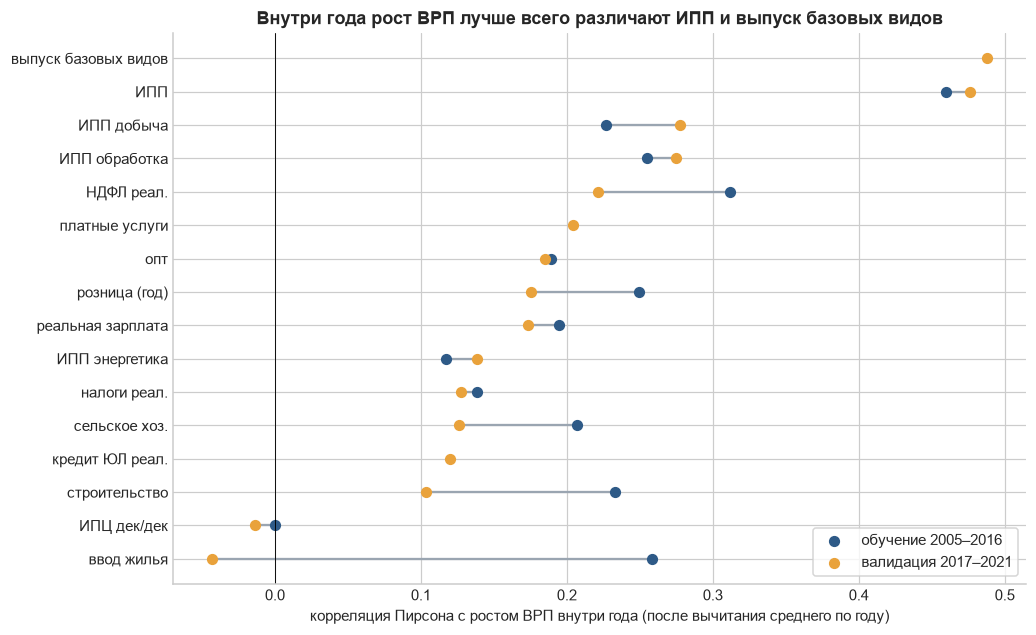

In [61]:
corr_plot = corr_features.drop(index=['ВВП']).sort_values('r_pearson внутри года (вал.)')
y = np.arange(corr_plot.shape[0])

fig, ax = plt.subplots(figsize=(10, 6.5))
for i in range(corr_plot.shape[0]):
    r_train = corr_plot['r_pearson внутри года (обуч.)'].iloc[i]
    r_val = corr_plot['r_pearson внутри года (вал.)'].iloc[i]
    if not np.isnan(r_train):
        ax.plot([r_train, r_val], [i, i], color=color_grey, lw=1.5, zorder=1)
ax.scatter(corr_plot['r_pearson внутри года (обуч.)'], y, color=period_colors['обучение'], s=40, zorder=2, label='обучение 2005–2016')
ax.scatter(corr_plot['r_pearson внутри года (вал.)'], y, color=period_colors['валидация'], s=40, zorder=2, label='валидация 2017–2021')
ax.axvline(0, color='black', lw=0.6)
ax.set_yticks(y)
ax.set_yticklabels(corr_plot.index)
ax.set_xlabel('корреляция Пирсона с ростом ВРП внутри года (после вычитания среднего по году)')
ax.set_title('Внутри года рост ВРП лучше всего различают ИПП и выпуск базовых видов')
ax.legend(loc='lower right', frameon=True)
plt.show()

ИПП самый сильный признак внутри года и при этом стабильный: корреляция 0,46 на обучении и 0,48 на валидации, по рангам 0,46 и 0,5. Рядом с ним выпуск по базовым видам: 0,49 на валидации, по рангам 0,55. Этот ряд есть только с 2018 года, 2018 год ушёл на пороги винзоризации, так что проверка идёт на 2019–2021 годах. Дальше идут добыча и обработка (0,23–0,28), реальный НДФЛ (0,31 на обучении и 0,22 на валидации, по рангам 0,28 и 0,27) и сельское хозяйство (0,21 и 0,13).

Без вычитания года картина обманчива. Розница даёт 0,56 по панели и только 0,25 внутри года, у ВВП корреляция с целью 0,62, а внутри года по построению ноль. Большая часть дисперсии признаков в панели приходится на общий годовой шок, который ВВП и так показывает.

Ранговая корреляция показывает, где связь держится на нескольких крайних значениях. У платных услуг на валидации 0,20 по Пирсону и 0,12 по рангам, у розницы 0,18 и 0,11, у ввода жилья на обучении 0,26 и 0,10. Ввод жилья к тому же на валидации уходит ниже нуля (−0,04), строительство с 0,23 до 0,1. ИПЦ с ростом ВРП внутри года не связан.

Даже лучший признак объясняет около четверти дисперсии внутри года ($0,48^2 = 0,23$).

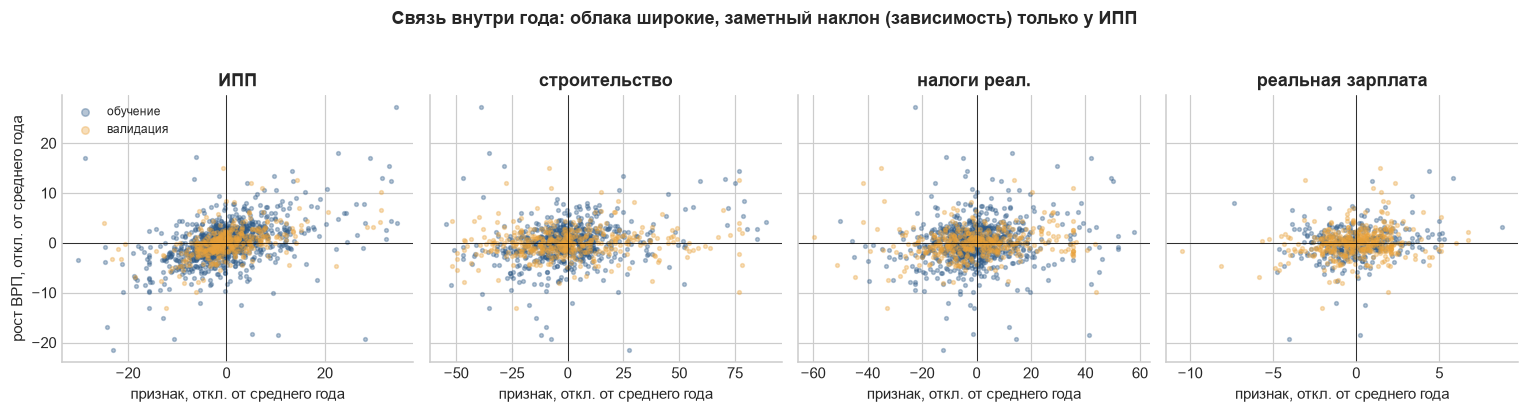

In [62]:
top_features = ['ИПП', 'строительство', 'налоги реал.', 'реальная зарплата']

fig, ax = plt.subplots(1, 4, figsize=(14, 3.6), sharey=True)
for i in range(len(top_features)):
    f = top_features[i]
    for years, label in periods[:2]:
        z = features_w[features_w['year'].between(*years)][[f, 'g', 'year']].dropna()
        z = z - z.groupby('year').transform('mean')
        ax[i].scatter(z[f], z['g'], s=6, alpha=0.35, color=period_colors[label], label=label)
    ax[i].axhline(0, color='black', lw=0.5)
    ax[i].axvline(0, color='black', lw=0.5)
    ax[i].set_title(f)
    ax[i].set_xlabel('признак, откл. от среднего года')
ax[0].set_ylabel('рост ВРП, откл. от среднего года')
ax[0].legend(fontsize=8, markerscale=2)
plt.suptitle('Связь внутри года: облака широкие, заметный наклон (зависимость) только у ИПП', fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

## 6. Пространственная зависимость

Вопрос к EDA 5 предполагает, что связи между регионами несут сигнал. Для проверки я выбрал глобальный индекс Морана для роста ВРП по годам с матрицей соседства queen (регионы с общей границой), строки нормировал. Крым и Севастополь в матрице отсутствуют, Калининградская и Сахалинская области не имеют соседей по суше.

Индекс Морана — это статистический показатель, который измеряет пространственную автокорреляцию данных, то есть показывает, насколько похожи или различны объекты в зависимости от их расположения на карте.

Значение индекса обычно лежит в диапазоне от -1 до +1:
- Ближе к +1 — указывает на кластеризацию (похожие значения располагаются рядом: например, богатые районы граничат с богатыми, а бедные — с бедными).
- Около 0 — указывает на случайное распределение (никакой пространственной связи между объектами нет).
- Ближе к -1 — указывает на регулярное или шахматное распределение.

In [63]:
# матрица соседства queen, строки нормированы
w_ids = sorted(sample_ids & set(region_geo['region_id']))
neighbors = adjacency[adjacency['region_id'].isin(w_ids) & adjacency['neighbor_id'].isin(w_ids) & (adjacency['contiguous_queen'] == 1)]
position = {}
for i in range(len(w_ids)):
    position[w_ids[i]] = i

w_matrix = np.zeros((len(w_ids), len(w_ids)))
for r, n in zip(neighbors['region_id'], neighbors['neighbor_id']):
    w_matrix[position[r], position[n]] = 1
w_matrix = np.maximum(w_matrix, w_matrix.T)

keep = w_matrix.sum(axis=1) > 0
w_matrix = w_matrix[keep][:, keep]
w_ids = [w_ids[i] for i in range(len(w_ids)) if keep[i]]
w_matrix = w_matrix / w_matrix.sum(axis=1, keepdims=True)
print(f'Регионов в матрице: {len(w_ids)}', f'Среднее число соседей: {round((w_matrix > 0).sum(axis=1).mean(), 1)}', sep='\n')

Регионов в матрице: 81
Среднее число соседей: 4.7


In [64]:
def moran(x, w, perms=999):
    z = x - x.mean()
    i_real = len(x) / w.sum() * (z @ w @ z) / (z @ z)
    sims = np.empty(perms)
    for k in range(perms):
        zp = rng.permutation(z)
        sims[k] = len(x) / w.sum() * (zp @ w @ zp) / (zp @ zp)
    p = (np.sum(sims >= i_real) + 1) / (perms + 1)
    return i_real, p

In [65]:
moran_years = pd.DataFrame(columns=['I', 'p', 'n'])
for year in range(2005, 2025):
    s = grp_sample[grp_sample['year'] == year].set_index('region_id')['g'].reindex(w_ids)
    ok = s.notna().values
    if ok.sum() < 60:
        continue
    w_year = w_matrix[ok][:, ok]
    row_sums = w_year.sum(axis=1, keepdims=True)
    w_year = w_year / np.where(row_sums == 0, 1, row_sums)
    i_real, p = moran(s.values[ok], w_year)
    moran_years.loc[year] = [i_real, p, ok.sum()]
moran_years.index.name = 'year'
moran_years = moran_years.astype(float)

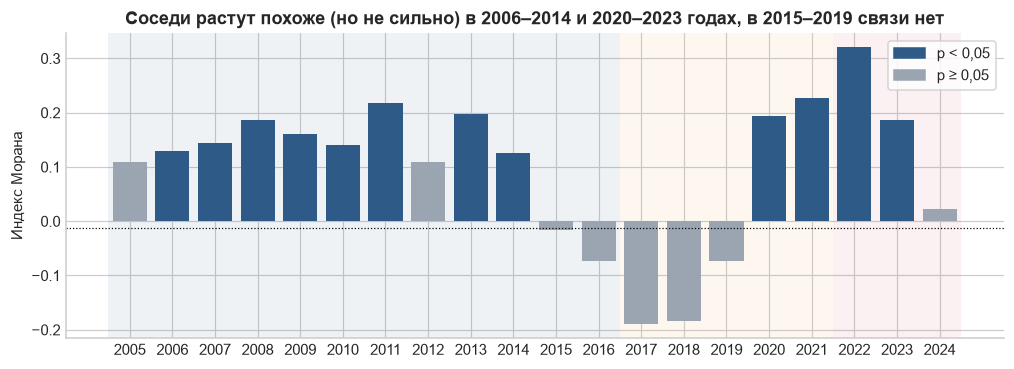

In [66]:
moran_colors = []
for p in moran_years['p']:
    if p < 0.05:
        moran_colors.append(color_main)
    else:
        moran_colors.append(color_grey)

fig, ax = plt.subplots(figsize=(11, 3.6))
shade_periods(ax)
ax.bar(moran_years.index.astype(int), moran_years['I'], color=moran_colors)
ax.set_xticks(moran_years.index.astype(int))
ax.set_xticklabels(moran_years.index.astype(int))
ax.axhline(-1 / (len(w_ids) - 1), color='black', lw=0.8, ls=':')
ax.set_ylabel('Индекс Морана')
ax.set_title('Соседи растут похоже (но не сильно) в 2006–2014 и 2020–2023 годах, в 2015–2019 связи нет')
ax.legend(handles=[mpl.patches.Patch(color=color_main, label='p < 0,05'), mpl.patches.Patch(color=color_grey, label='p ≥ 0,05')], frameon=True)
plt.show()

In [67]:
moran_years.T.round(3)

year,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
I,0.11,0.13,0.14,0.19,0.16,0.14,0.22,0.11,0.20,0.12,-0.02,-0.07,-0.19,-0.18,-0.07,0.19,0.23,0.32,0.19,0.02
p,0.06,0.03,0.04,0.01,0.01,0.03,0.01,0.07,0.01,0.04,0.50,0.78,1.00,0.99,0.79,0.01,0.00,0.00,0.01,0.29
n,78.00,79.00,79.00,79.00,79.00,79.00,79.00,81.00,81.00,81.00,81.00,81.00,81.00,81.00,81.00,81.00,81.00,81.00,81.00,81.00


In [68]:
# корреляция отклонений от медианы года между парами регионов в зависимости от расстояния (2005–2021)
grp_dist = grp_sample[grp_sample['year'].between(train_years[0], val_years[1])].copy()
grp_dist['dev'] = grp_dist['g'] - grp_dist.groupby('year')['g'].transform('median')
dev_matrix = grp_dist.pivot(index='year', columns='region_id', values='dev')
dev_matrix = dev_matrix.loc[:, dev_matrix.notna().sum() >= 15]
dev_corr = dev_matrix.corr(min_periods=12)

region_pairs = adjacency[adjacency['region_id'].isin(dev_corr.columns) & adjacency['neighbor_id'].isin(dev_corr.columns)
                         & (adjacency['region_id'] < adjacency['neighbor_id'])].copy()
pair_corr = []
for a, b in zip(region_pairs['region_id'], region_pairs['neighbor_id']):
    pair_corr.append(dev_corr.loc[a, b])
region_pairs['corr'] = pair_corr
region_pairs['dist_bin'] = pd.cut(region_pairs['centroid_distance_km'], [0, 500, 1000, 1500, 2500, 4000, 8000])

distance_corr = region_pairs.groupby('dist_bin', observed=True)['corr'].agg(['mean', 'median', 'count'])
distance_corr.loc['соседи'] = region_pairs[region_pairs['contiguous_queen'] == 1]['corr'].agg(['mean', 'median', 'count']).values

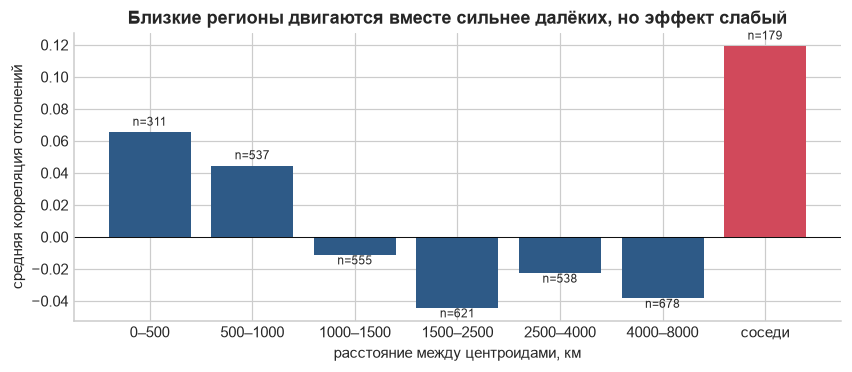

In [69]:
bar_labels = [f'{int(i.left)}–{int(i.right)}' for i in distance_corr.index[:-1]] + ['соседи']
bar_colors = [color_main] * (distance_corr.shape[0] - 1) + [color_accent]

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(range(distance_corr.shape[0]), distance_corr['mean'], color=bar_colors)
for i in range(distance_corr.shape[0]):
    m = distance_corr['mean'].iloc[i]
    n = distance_corr['count'].iloc[i]
    if m >= 0:
        ax.text(i, m + 0.004, f'n={int(n)}', ha='center', fontsize=8)
    else:
        ax.text(i, m - 0.006, f'n={int(n)}', ha='center', fontsize=8)
ax.set_xticks(range(distance_corr.shape[0]))
ax.set_xticklabels(bar_labels)
ax.axhline(0, color='black', lw=0.6)
ax.set_xlabel('расстояние между центроидами, км')
ax.set_ylabel('средняя корреляция отклонений')
ax.set_title('Близкие регионы двигаются вместе сильнее далёких, но эффект слабый')
plt.show()

In [70]:
distance_corr

,mean,median,count
dist_bin,,,
"(0, 500]",0.07,0.07,311
"(500, 1000]",0.04,0.03,537
"(1000, 1500]",-0.01,-0.00,555
"(1500, 2500]",-0.04,-0.04,621
"(2500, 4000]",-0.02,-0.02,538
"(4000, 8000]",-0.04,-0.05,678
соседи,0.12,0.14,179


In [71]:
# пузырьковая карта по центроидам: средний рост относительно медианы года и его волатильность (2005–2021)
name_to_id = {}
for k in region_names:
    name_to_id[region_names[k]] = k

bubble = volatility.copy()
bubble['region_id'] = [name_to_id[n] for n in bubble.index]
bubble = bubble.merge(region_geo[['region_id', 'lon', 'lat']], on='region_id', how='left')
bubble['lon'] = np.where(bubble['lon'] < 0, bubble['lon'] + 360, bubble['lon'])

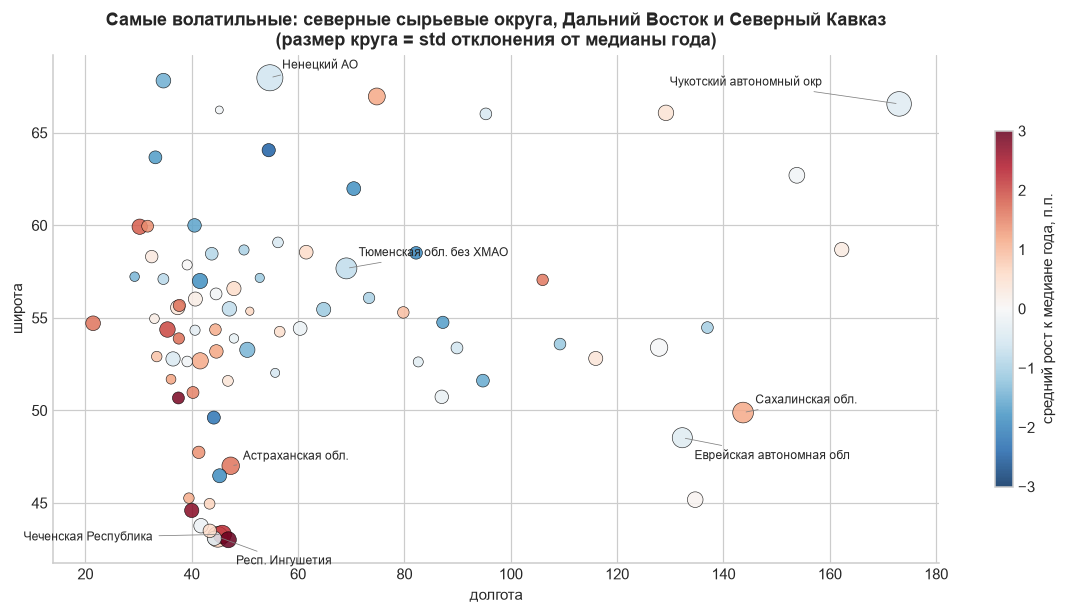

In [72]:
fig, ax = plt.subplots(figsize=(13, 6))
sc = ax.scatter(bubble['lon'], bubble['lat'], s=bubble['std'] * 25, c=bubble['mean'], cmap='RdBu_r', vmin=-3, vmax=3,
                edgecolor='black', linewidth=0.4, alpha=0.85)

top_volatile = bubble.sort_values('std', ascending=False).head(8)
offsets = [(8, 6), (-150, 12), (8, 8), (8, 6), (12, -18), (8, -14), (-130, -4), (8, 4)]
for i in range(top_volatile.shape[0]):
    r = top_volatile.iloc[i]
    label = region_names[r['region_id']].replace(' область', ' обл.').replace('Республика ', 'Респ. ')[:24]
    ax.annotate(label, (r['lon'], r['lat']), xytext=offsets[i], textcoords='offset points', fontsize=8,
                arrowprops={'arrowstyle': '-', 'color': 'gray', 'lw': 0.5})
cb = plt.colorbar(sc, ax=ax, shrink=0.7)
cb.set_label('средний рост к медиане года, п.п.')
ax.set_xlabel('долгота')
ax.set_ylabel('широта')
ax.set_title('Самые волатильные: северные сырьевые округа, Дальний Восток и Северный Кавказ\n(размер круга = std отклонения от медианы года)')
plt.show()

Пространственная зависимость есть, но непостоянная и слабая. Индекс Морана положителен и значим (p < 0,05) в 2006–2011, 2013–2014 и 2020–2023 годах, его значения 0,12–0,32. В 2015–2019 годах связи нет, а в 2017–2018 годах индекс Морана отрицателен (−0,19 и −0,18). Корреляция отклонений у соседей по границе 0,12, у регионов ближе 500 км 0,07, дальше 1500 км около нуля и слегка ниже.

Для пятого вопроса к EDA это значит, что сигнал от соседей стоит ждать прежде всего в годы общих шоков (2009, 2020, 2022).

Волатильность сосредоточена в трёх зонах: северные сырьевые округа, Дальний Восток и Северный Кавказ.

## 7. Шоки 2020 и 2022 годов

Регионы разбиты на квантили по 33% по доле добычи в ВРП за 2019 год (последний год, опубликованный к 2021 году) и по доле обработки.

In [73]:
shares_2019 = annual.xs(2019, level='year')[['grp_share_dobycha_poleznykh_iskopaemykh', 'grp_share_obrabatyvayushchie_proizvodstva']].copy()
shares_2019.columns = ['добыча', 'обработка']
shares_2019['тип'] = 'прочие'
shares_2019.loc[shares_2019['добыча'] >= shares_2019['добыча'].quantile(2 / 3), 'тип'] = 'сырьевые (верхняя треть по добыче)'
shares_2019.loc[(shares_2019['тип'] == 'прочие') & (shares_2019['обработка'] >= shares_2019['обработка'].quantile(2 / 3)), 'тип'] = 'промышленные (обработка)'

grp_shocks = grp_sample[grp_sample['year'].between(2019, 2024)].merge(shares_2019['тип'].reset_index(), on='region_id')

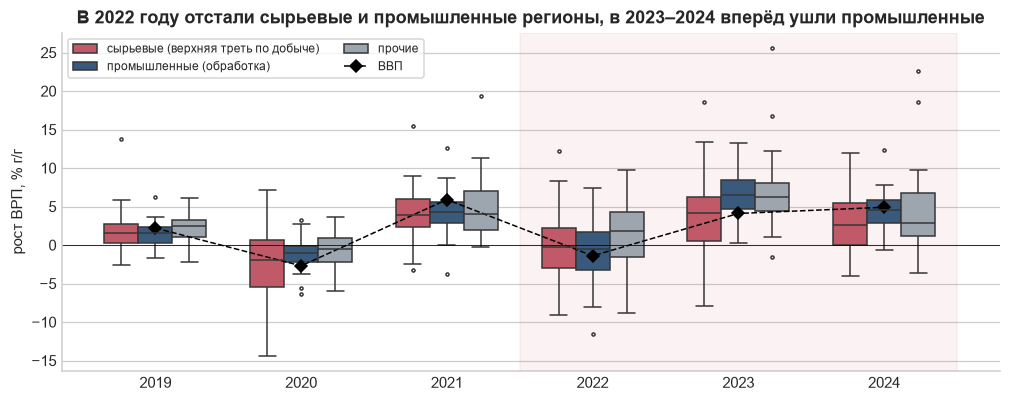

In [74]:
region_types = ['сырьевые (верхняя треть по добыче)', 'промышленные (обработка)', 'прочие']

fig, ax = plt.subplots(figsize=(11, 4))
sns.boxplot(data=grp_shocks, x='year', y='g', hue='тип', ax=ax, palette=[color_accent, color_main, color_grey], fliersize=2, width=0.7,
            hue_order=region_types)
ax.plot(range(6), [gdp_growth[y] for y in range(2019, 2025)], color='black', marker='D', lw=1, ls='--', label='ВВП')
ax.axhline(0, color='black', lw=0.5)
ax.axvspan(2.5, 5.5, color=period_colors['тест'], alpha=0.07)
ax.set_xlabel('')
ax.set_ylabel('рост ВРП, % г/г')
ax.set_title('В 2022 году отстали сырьевые и промышленные регионы, в 2023–2024 вперёд ушли промышленные')
ax.legend(fontsize=8, loc='upper left', ncol=2, frameon=True)
plt.show()

In [75]:
grp_shocks.groupby(['year', 'тип'])['g'].median().unstack().round(1)

тип,промышленные (обработка),прочие,сырьевые (верхняя треть по добыче)
year,,,
2019,1.50,2.50,1.60
2020,-1.00,-0.50,-2.00
2021,4.30,4.00,3.90
2022,-0.50,1.80,-0.30
2023,6.50,6.30,4.10
2024,4.50,2.80,2.60


Рост медианного региона в 2022 году: сырьевые −0,3%, промышленные −0,5%, прочие +1,8%. В 2023 году промышленные ушли вперёд (+6,5% против +4,1% у сырьевых), в 2024 году разрыв сохранился (+4,5% против +2,6%). В 2020 году сильнее всех упали и сильнее всех разошлись сырьевые регионы.

## 8. Национальные факторы

Общие для всех регионов ряды: ключевая ставка, курс доллара, нефть Brent и индикатор бизнес-климата Банка России.

In [76]:
national = national_monthly.copy()
national['date'] = pd.to_datetime(dict(year=national['year'].astype(int), month=national['month'].astype(int), day=1))
national = national[national['date'] >= '2005-01-01'].set_index('date')

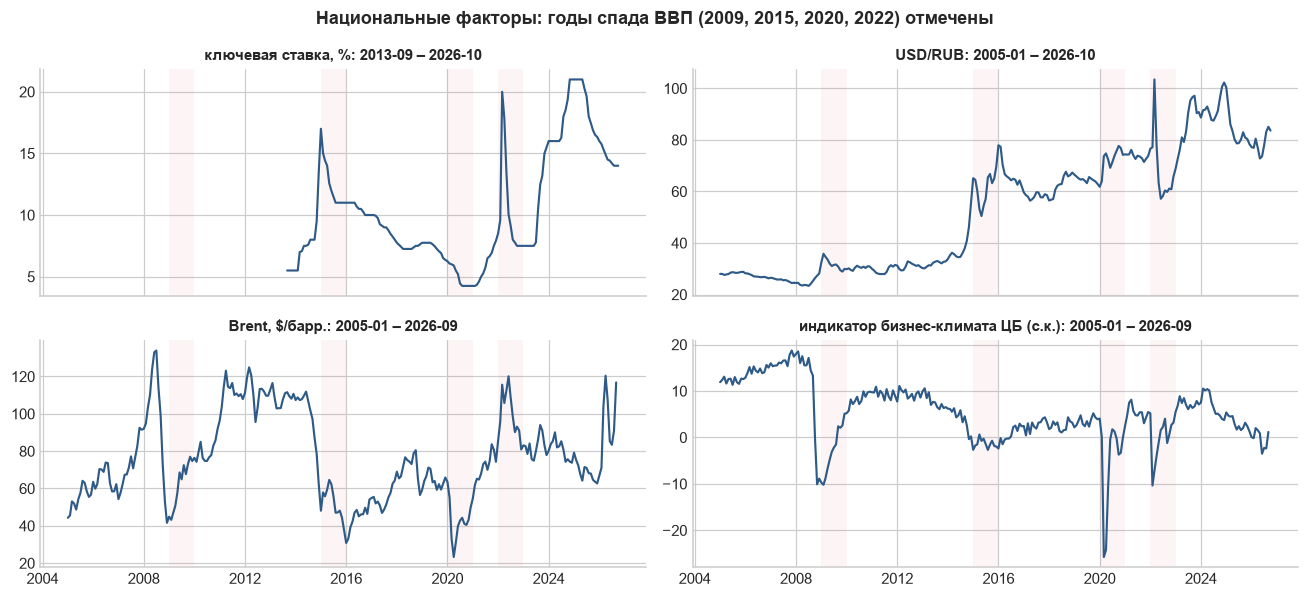

In [77]:
national_series = {'key_rate_avg': 'ключевая ставка, %', 'usd_rub_avg': 'USD/RUB', 'wb_crude_oil_brent': 'Brent, $/барр.',
                   'ibk_total_sa': 'индикатор бизнес-климата ЦБ (с.к.)'}
series_names = list(national_series)

k = 0
fig, ax = plt.subplots(2, 2, figsize=(12, 5.5), sharex=True)
for i in range(2):
    for j in range(2):
        c = series_names[k]
        s = national[c].dropna()
        ax[i][j].plot(s.index, s, color=color_main, lw=1.4)
        for y in [2009, 2015, 2020, 2022]:
            ax[i][j].axvspan(pd.Timestamp(f'{y}-01-01'), pd.Timestamp(f'{y}-12-31'), color=color_accent, alpha=0.06, lw=0)
        ax[i][j].set_title(f'{national_series[c]}: {s.index.min():%Y-%m} – {s.index.max():%Y-%m}', fontsize=10)
        k += 1
plt.suptitle('Национальные факторы: годы спада ВВП (2009, 2015, 2020, 2022) отмечены', fontweight='bold')
plt.tight_layout()
plt.show()

In [78]:
national_coverage = pd.DataFrame(columns=['начало', 'конец'])
for c in national.columns:
    if c not in ('year', 'month'):
        national_coverage.loc[c] = [national[c].first_valid_index(), national[c].last_valid_index()]
national_coverage['начало'] = pd.to_datetime(national_coverage['начало'])
late_series = national_coverage[national_coverage['начало'] > '2005-01-01']
print(f'Национальных рядов: {national_coverage.shape[0]}', f'Из них начинаются позже 2005 года: {late_series.shape[0]}', sep='\n')
late_series

Национальных рядов: 126
Из них начинаются позже 2005 года: 12


,начало,конец
gdp_old_yoy_q,2005-03-01,2011-12-01
gdp_yoy_q,2012-03-01,2026-06-01
key_rate_avg,2013-09-01,2026-10-01
key_rate_eom,2013-09-01,2026-10-01
nonworking_paid_days,2010-01-01,2027-12-01
rf_ipp_energy_yoy,2015-01-01,2026-08-01
rf_ipp_manuf_yoy,2015-01-01,2026-08-01
rf_ipp_mining_yoy,2015-01-01,2026-08-01
rf_ipp_total_yoy,2015-01-01,2026-08-01
rf_ipp_water_yoy,2015-01-01,2026-08-01


Из 126 национальных рядов 12 начинаются позже 2005 года. Самое неудобное для обучения, что ключевая ставка есть только с сентября 2013 года. До этого нужна ставка рефинансирования или ставка межбанковского рынка, иначе денежные условия в обучающем окне не описать. Квартальный ВВП тоже меняет методологию (до 2011 года старый ряд, с 2012 года новый), ИПП РФ в ОКВЭД2 начинается с 2015 года.

## Анализ признаков

Дальше признаки рассматриваются в той же постановке, что и в разделе 5: годовые значения признаков и цели, из которых вычтено среднее по году. Так общий шок года (его в модели закрывает ВВП) не смешивается с различиями между регионами. Разности «год к прошлому году» не используются: рост ВРП почти не повторяется из года в год, поэтому разность добавляет шум прошлого года, а для перехода от разности обратно к росту нужен прошлогодний ВРП, которого на ранних датах оценки ещё нет.

Считаю на обучении и валидации, тест в этих расчётах не участвует. Признаки винзоризованы по порогам из раздела 5.

In [79]:
region_features = [f for f in feature_names if f != 'ВВП']  # региональные признаки без национального ВВП

# значения внутри года: из признаков и цели вычитаем среднее по году
within_year = features_w[features_w['year'].between(train_years[0], val_years[1])].copy()
within_year['period'] = within_year['year'].map(get_period)
within_year[region_features + ['g']] = within_year[region_features + ['g']] - within_year.groupby('year')[region_features + ['g']].transform('mean')

In [80]:
# признаки, у которых есть история в обучении (заполнено не меньше 60% строк обучения)
train_share = within_year[within_year['period'] == 'обучение'][region_features].notna().mean()
long_features = [f for f in region_features if train_share[f] >= 0.6]
print('Признаки с историей в обучении:', long_features)

Признаки с историей в обучении: ['ИПП', 'ИПП добыча', 'ИПП обработка', 'ИПП энергетика', 'строительство', 'опт', 'ИПЦ дек/дек', 'налоги реал.', 'НДФЛ реал.', 'сельское хоз.', 'розница (год)']


### 9. Корреляции признаков между собой

Проверяю, насколько признаки связаны друг с другом, корреляции внутри года на обучении и валидации и коэффициент VIF на обучении.

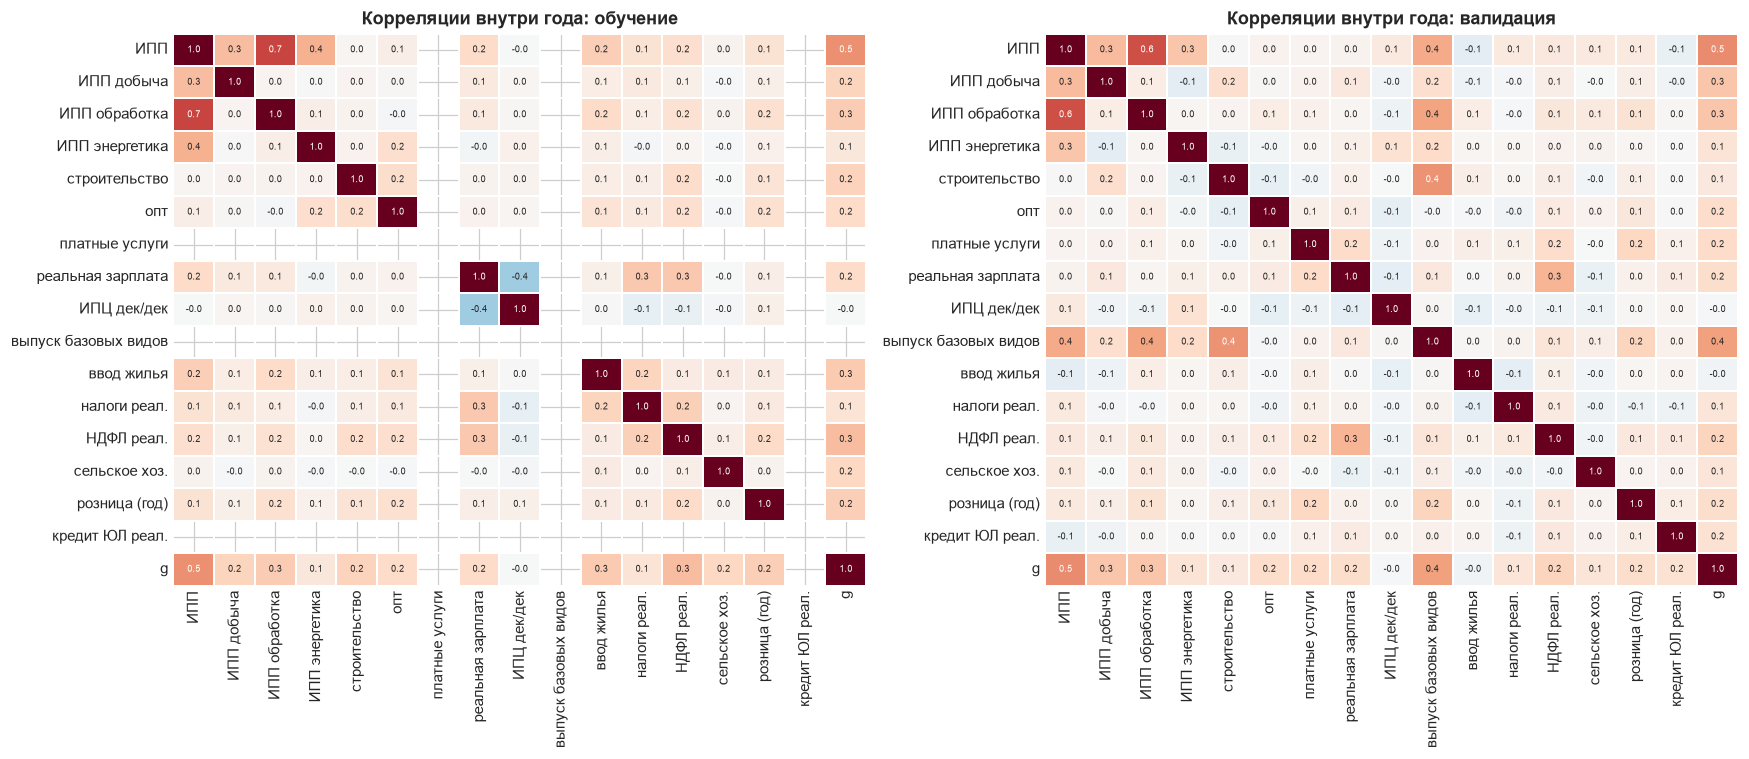

In [81]:
# корреляции признаков между собой внутри года
fig, ax = plt.subplots(1, 2, figsize=(16, 7))
for i in range(2):
    label = ['обучение', 'валидация'][i]
    correlation = within_year[within_year['period'] == label][region_features + ['g']].corr(min_periods=100)
    sns.heatmap(correlation, cmap='RdBu_r', vmin=-1, vmax=1, annot=True, fmt='.1f', annot_kws={'fontsize': 6},
                linewidths=0.3, linecolor='white', cbar=False, ax=ax[i])
    ax[i].set_title(f'Корреляции внутри года: {label}')
plt.tight_layout()
plt.show()

In [82]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

X_vif = sm.add_constant(within_year[within_year['period'] == 'обучение'][long_features].dropna())

vif = pd.DataFrame()
vif['Feature'] = X_vif.columns
vif['VIF'] = [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
vif = vif[vif['Feature'] != 'const'].sort_values('VIF', ascending=False)
print(f'VIF на обучении, {X_vif.shape[0]} строк без пропусков:')
vif.round(2)

VIF на обучении, 640 строк без пропусков:


,Feature,VIF
1,ИПП,2.72
3,ИПП обработка,2.17
4,ИПП энергетика,1.31
2,ИПП добыча,1.21
9,НДФЛ реал.,1.15
8,налоги реал.,1.10
11,розница (год),1.09
6,опт,1.09
5,строительство,1.06
7,ИПЦ дек/дек,1.04


Матрицы выше посчитаны на значениях внутри года. Сильно связаны только ИПП и ИПП обработки: 0,68 на обучении и 0,65 на валидации. Обработка составляет большую часть промышленности региона, так что это ожидаемо. Дальше идут ИПП с энергетикой и добычей (0,28–0,36), а на валидации выпуск по базовым видам со строительством (0,45) и с обработкой (0,41), потому что индекс базовых видов сам собран из этих отраслей. Реальная зарплата, НДФЛ и налоги связаны между собой на уровне 0,24–0,34. Остальные пары слабее 0,25.

Мультиколлинеарность проверяю через VIF. Обычный порог около 5. На обучении максимум у ИПП (2,7) и обработки (2,2), у остальных признаков меньше 1,4. Мультиколлинеарности нет. Стоит только помнить, что ИПП и его разделы частично повторяют друг друга, поэтому их коэффициенты в линейной модели по отдельности не будут интерпретироваться.

### 10. Распределения признаков

Таблица и графики построены на значениях внутри года, то есть после вычитания общего шока. Так видно, одинаково ли регионы отличаются друг от друга в разные периоды, а не насколько сменился общий фон (инфляция, шоки). Тестовый период не используется. Статистика Колмогорова–Смирнова показывает, насколько различаются распределения обучения и валидации - 0 означает полное совпадение, 1 полное несовпадение.

In [83]:
# форма распределений: признаки внутри года, обучение против валидации
train_part = within_year[within_year['period'] == 'обучение']
val_part = within_year[within_year['period'] == 'валидация']

dist = pd.DataFrame(columns=['n обуч.', 'std обуч.', 'асимм. обуч.', 'эксцесс обуч.',
                             'n вал.', 'std вал.', 'асимм. вал.', 'эксцесс вал.', 'KS', 'p KS'])
for f in region_features + ['g']:
    a = train_part[f].dropna()
    b = val_part[f].dropna()
    row = [np.nan] * 10
    if a.shape[0] >= 60:
        row[0:4] = [a.shape[0], a.std(), stats.skew(a), stats.kurtosis(a)]
    if b.shape[0] >= 60:
        row[4:8] = [b.shape[0], b.std(), stats.skew(b), stats.kurtosis(b)]
    if a.shape[0] >= 60 and b.shape[0] >= 60:
        result_ks = stats.ks_2samp(a, b)
        row[8:10] = [result_ks.statistic, result_ks.pvalue]
    dist.loc[f] = row
dist.index.name = 'признак'
dist = dist.astype(float)
dist.round(2)

,n обуч.,std обуч.,асимм. обуч.,эксцесс обуч.,n вал.,std вал.,асимм. вал.,эксцесс вал.,KS,p KS
признак,,,,,,,,,,
ИПП,976.00,7.97,0.73,3.33,425.00,6.84,0.90,4.85,0.07,0.10
ИПП добыча,983.00,19.77,1.39,4.45,415.00,16.05,1.49,6.83,0.06,0.31
ИПП обработка,994.00,9.36,0.26,1.76,425.00,8.49,0.43,3.41,0.08,0.06
ИПП энергетика,992.00,10.02,2.54,11.84,425.00,9.83,2.39,11.06,0.03,0.99
строительство,660.00,19.51,1.12,3.83,425.00,24.37,0.78,1.12,0.10,0.01
опт,658.00,22.43,3.36,16.63,425.00,16.47,3.48,23.68,0.13,0.00
платные услуги,NaN,NaN,NaN,NaN,425.00,4.04,0.86,6.65,NaN,NaN
реальная зарплата,334.00,2.03,0.43,1.26,425.00,1.99,-0.39,2.67,0.07,0.30
ИПЦ дек/дек,992.00,1.42,0.25,2.41,425.00,0.70,-0.66,7.68,0.25,0.00


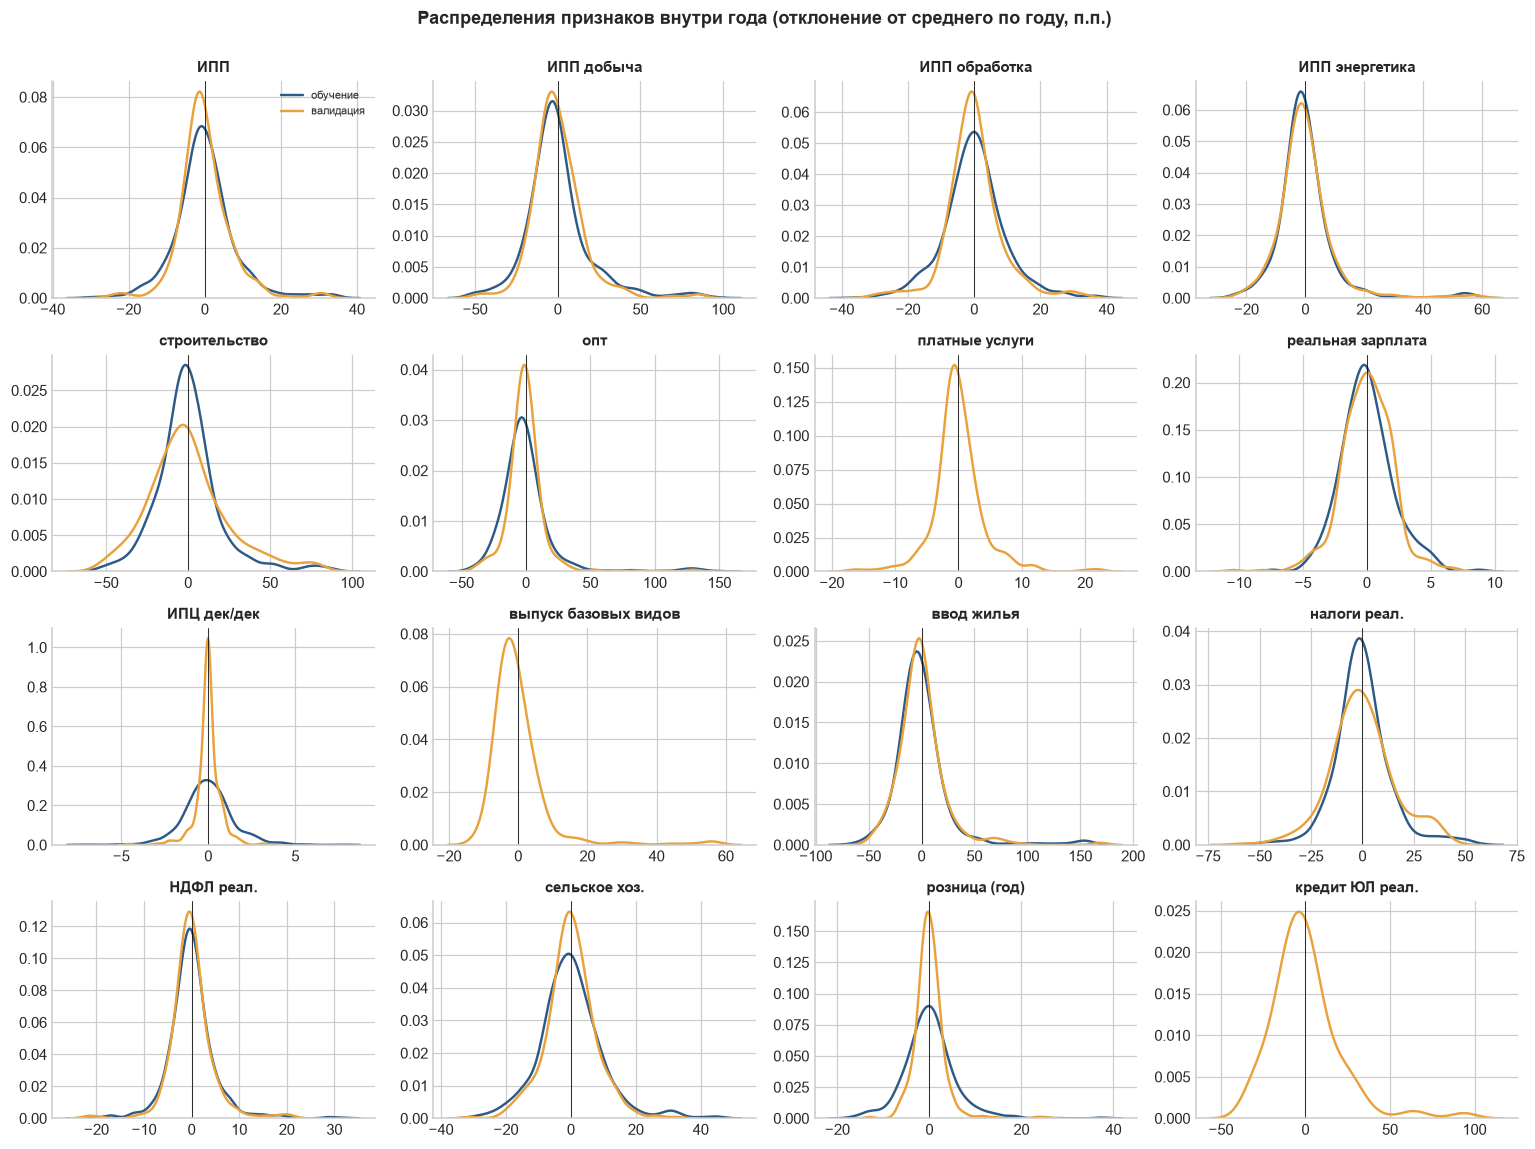

In [84]:
k = 0
fig, ax = plt.subplots(4, 4, figsize=(14, 10.4))
for i in range(4):
    for j in range(4):
        f = region_features[k]
        for label in ['обучение', 'валидация']:
            s = within_year[within_year['period'] == label][f].dropna()
            if s.shape[0] >= 60 and s.std() > 0:
                sns.kdeplot(s, ax=ax[i][j], color=period_colors[label], lw=1.6, label=label)
        ax[i][j].axvline(0, color='black', lw=0.5)
        ax[i][j].set_title(f, fontsize=10)
        ax[i][j].set_xlabel('')
        ax[i][j].set_ylabel('')
        k += 1
ax[0][0].legend(fontsize=7)
plt.suptitle('Распределения признаков внутри года (отклонение от среднего по году, п.п.)', y=1.00, fontweight='bold')
plt.tight_layout()
plt.show()

**Хвосты.** Даже после винзоризации у многих признаков тяжёлые хвосты. Эксцесс у энергетики 11–12, у опта 17–24, у ввода жилья около 14, у выпуска базовых видов 20, у НДФЛ около 7 (у нормального распределения 0). Отдельные регион-годы сильно отличаются от остальных и могут перетянуть коэффициенты на себя. Это решается предобработкой и функцией потерь, а именно логарифмирование, обрезка по порогам обучения и функция Хьюбера.

**Сдвиг между периодами.** У промышленности распределения почти не меняются. Статистика Колмогорова-Смирнова 0,03–0,08, различие незначимо или на границе значимости. Заметнее сдвинулись ИПЦ (KS 0,25, разброс между регионами на валидации вдвое уже - 0,7 против 1,4 п.п.), розница (0,16, разброс 3,3 против 5,6 п.п.), опт (0,13, разброс 16 против 22 п.п.) и сельское хозяйство (0,09). У строительства (0,10) наоборот: на валидации регионы расходятся сильнее, 24 против 20 п.п. Сама цель на валидации тоже уже: разброс 2,9 п.п. против 4,2 на обучении. В 2017–2021 годах регионы в целом расходились меньше, чем в 2005–2016 годах, поэтому ошибка на валидации может оказаться ниже, чем потом на кризисных годах теста.

**Вывод.** Распределения промышленных признаков стабильны. У торговли, сельского хозяйства и ИПЦ различия между регионами на валидации меньше, чем на обучении, у строительства больше. Тяжёлые хвосты требуют обрезки или робастной функции потерь.

Несмотря на это, вместо  разделения на периоды обучения и валидации, можно попробовать валидацию скользящим окном.

## 11. Датасет

Собираю одну таблицу «регион x год» для моделей: цель, признаки из раздела 5, национальные ряды, структурные веса ВРП и служебные столбцы.

Что в таблице уже сделано, а что нет:

- сделано: склейка ОКВЭД-2007 и ОКВЭД2, нули и бесконечности заменены на пропуски, рублёвые ряды переведены в реальный рост через ИПЦ, всё переведено в прирост в п.п.;
- не сделано: винзоризация, логарифмирование, стандартизация, вычитание среднего по году.

Значения в таблице соответствуют полному году.

In [85]:
# названия столбцов итогового датасета
rename_features = {'ИПП': 'ipp_total', 'ИПП добыча': 'ipp_mining', 'ИПП обработка': 'ipp_manuf', 'ИПП энергетика': 'ipp_energy',
                   'строительство': 'constr', 'опт': 'wholesale', 'платные услуги': 'services', 'реальная зарплата': 'wage_real',
                   'ИПЦ дек/дек': 'cpi_dec', 'выпуск базовых видов': 'bvd', 'ввод жилья': 'housing', 'налоги реал.': 'tax_total_real',
                   'НДФЛ реал.': 'tax_ndfl_real', 'сельское хоз.': 'agri', 'розница (год)': 'retail',
                   'кредит ЮЛ реал.': 'loans_corp_real', 'ВВП': 'gdp'}


def get_split(year):
    if get_period(year) == 'обучение':
        return 'train'
    elif get_period(year) == 'валидация':
        return 'val'
    elif get_period(year) == 'тест':
        return 'test'
    elif year == 2025:
        return 'holdout'
    else:
        return 'other'

In [86]:
# 85 единиц x годы 2005–2025
grid = sample_regions[['region_id', 'name_short', 'fd']].rename(columns={'name_short': 'region_name'})
grid = grid.merge(pd.DataFrame({'year': range(2005, 2026)}), how='cross')
grid['split'] = grid['year'].map(get_split)
grid['okved2'] = (grid['year'] >= 2017).astype(int)  # 0 = ОКВЭД-2007, 1 = ОКВЭД2

# цель и признаки из раздела 5
target_panel = grp_sample[['region_id', 'year', 'g']].rename(columns={'g': 'grp_g'})
features_panel = features.rename(columns=rename_features)[['region_id', 'year'] + list(rename_features.values())]
water = (december['ipp_water_ytd_yoy'] - 100).rename('ipp_water').reset_index()

In [87]:
# ИПП РФ за год
rf_long = monthly_long[monthly_long['region_id'].str.startswith('rossiyskaya_federatsiya') & (monthly_long['month'] == 12)
                       & monthly_long['feature'].isin(['ipp_total_ytd_yoy', 'ipp_total_okved1_ytd_yoy'])]
rf_wide = rf_long.pivot_table(index='year', columns=['feature', 'region_id'], values='value')
rf_new = rf_wide['ipp_total_ytd_yoy'].bfill(axis=1).iloc[:, 0]        # первая непустая строка РФ
rf_old = rf_wide['ipp_total_okved1_ytd_yoy'].bfill(axis=1).iloc[:, 0]
rf_ipp = rf_new.where(rf_new.index > 2016).fillna(rf_old.where(rf_old.index <= 2016)) - 100
rf_ipp.index = rf_ipp.index.astype(int)

In [88]:
# доли разделов в ВРП за год t−2
share_columns = {'mining': ['grp_share_dobycha_poleznykh_iskopaemykh', ['grp_share_okved1_razdel_s_dobycha_poleznykh_iskopaemykh']],
                 'manuf': ['grp_share_obrabatyvayushchie_proizvodstva', ['grp_share_okved1_razdel_d_obrabatyvayushchie_proizvodstva']],
                 'energy': ['grp_share_obespechenie_elektricheskoy_energiey_gaz', ['grp_share_okved1_razdel_e_proizvodstvo_i_raspredelenie_el']],
                 'water': ['grp_share_vodosnabzhenie_vodootvedenie_organizatsi', []],
                 'constr': ['grp_share_stroitelstvo', ['grp_share_okved1_razdel_f_stroitelstvo']],
                 'agri': ['grp_share_selskoe_lesnoe_khozyaystvo_okhota_rybolo',
                          ['grp_share_okved1_razdel_a_selskoe_khozyaystvo_okhota_i_le', 'grp_share_okved1_razdel_b_rybolovstvo_rybovodstvo']],
                 'trade': ['grp_share_torgovlya_optovaya_i_roznichnaya_remont_', ['grp_share_okved1_razdel_g_optovaya_i_roznichnaya_torgovly']]}

shares = pd.DataFrame(index=annual.index)
for k in share_columns:
    new, old = share_columns[k]
    if len(old) > 0:
        s_old = annual[old].sum(axis=1, min_count=len(old))
    else:
        s_old = pd.Series(np.nan, index=annual.index)
    shares[f'share_{k}_t2'] = annual[new].fillna(s_old)
shares['grp_nominal_t2'] = annual['grp_nominal_rub'].fillna(annual['grp_nominal_okved1_rub'])
shares = shares.reset_index()
shares['year'] = shares['year'] + 2  # значение года t−2 ставим в строку года t

In [89]:
# средний ИПП у соседей по общей границе в тот же год
neighbor_pairs = adjacency[(adjacency['contiguous_queen'] == 1) & adjacency['region_id'].isin(sample_ids)
                           & adjacency['neighbor_id'].isin(sample_ids)][['region_id', 'neighbor_id']]
neighbor_ipp = features_panel[['region_id', 'year', 'ipp_total']].rename(columns={'region_id': 'neighbor_id'})
neighbor_ipp = neighbor_pairs.merge(neighbor_ipp, on='neighbor_id')
neighbor_ipp = neighbor_ipp.groupby(['region_id', 'year'])['ipp_total'].mean().rename('ipp_total_nbr').reset_index()

In [90]:
panel = grid.merge(target_panel, on=['region_id', 'year'], how='left')
panel = panel.merge(features_panel, on=['region_id', 'year'], how='left')
panel = panel.merge(water, on=['region_id', 'year'], how='left')
panel = panel.merge(shares, on=['region_id', 'year'], how='left')
panel = panel.merge(neighbor_ipp, on=['region_id', 'year'], how='left')
panel['gdp'] = panel['year'].map(gdp_growth)
panel['ipp_total_rf'] = panel['year'].map(rf_ipp)

panel_columns = ['region_id', 'region_name', 'fd', 'year', 'split', 'okved2', 'grp_g', 'gdp',
                 'ipp_total', 'ipp_mining', 'ipp_manuf', 'ipp_energy', 'ipp_water', 'ipp_total_rf', 'ipp_total_nbr',
                 'tax_ndfl_real', 'tax_total_real', 'wholesale', 'wage_real', 'retail', 'agri', 'constr', 'services',
                 'bvd', 'loans_corp_real', 'housing', 'cpi_dec'] + [f'share_{k}_t2' for k in share_columns] + ['grp_nominal_t2']
panel = panel[panel_columns].sort_values(['region_id', 'year']).reset_index(drop=True)
panel.shape

(1785, 35)

In [91]:
panel.to_parquet(path_processed / 'model_panel_annual.parquet', index=False)
panel.to_csv(path_processed / 'model_panel_annual.csv.gz', index=False, compression='gzip')
panel.head(10)

,region_id,region_name,fd,year,split,okved2,grp_g,gdp,ipp_total,ipp_mining,ipp_manuf,ipp_energy,ipp_water,ipp_total_rf,ipp_total_nbr,tax_ndfl_real,tax_total_real,wholesale,wage_real,retail,agri,constr,services,bvd,loans_corp_real,housing,cpi_dec,share_mining_t2,share_manuf_t2,share_energy_t2,share_water_t2,share_constr_t2,share_agri_t2,share_trade_t2,grp_nominal_t2
0,altayskiy_kray,Алтайский край,Сибирский федеральный округ,2005,train,0,1.60,6.40,-5.00,17.66,-5.97,-2.60,NaN,5.10,1.65,NaN,NaN,NaN,NaN,12.50,-8.90,NaN,NaN,NaN,NaN,NaN,13.64,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,altayskiy_kray,Алтайский край,Сибирский федеральный округ,2006,train,0,10.20,8.20,10.26,74.21,12.66,1.10,NaN,6.30,7.64,NaN,NaN,NaN,NaN,19.60,9.40,NaN,NaN,NaN,NaN,NaN,7.72,0.15,17.04,5.42,NaN,3.98,23.28,19.19,"114,840,483.40"
2,altayskiy_kray,Алтайский край,Сибирский федеральный округ,2007,train,0,9.50,8.50,13.50,38.90,14.40,7.00,NaN,6.80,6.63,21.67,18.49,NaN,NaN,15.30,8.60,NaN,NaN,NaN,NaN,NaN,12.10,0.19,19.36,5.68,NaN,4.73,16.85,21.73,"135,686,442.20"
3,altayskiy_kray,Алтайский край,Сибирский федеральный округ,2008,train,0,3.30,5.20,3.30,28.80,2.00,5.00,NaN,0.60,1.93,12.07,10.77,NaN,NaN,12.00,-6.80,NaN,NaN,NaN,NaN,NaN,14.47,0.42,18.51,4.52,NaN,4.79,16.28,20.94,"173,810,522.00"
4,altayskiy_kray,Алтайский край,Сибирский федеральный округ,2009,train,0,-5.30,-7.80,-8.00,-5.90,-9.60,-1.60,NaN,-10.70,-10.20,-6.64,-21.28,-23.78,NaN,-17.50,18.30,-28.30,NaN,NaN,NaN,NaN,10.14,0.52,17.38,4.22,NaN,4.15,15.76,23.75,"223,563,406.20"
5,altayskiy_kray,Алтайский край,Сибирский федеральный округ,2010,train,0,3.20,4.50,22.00,-20.00,25.80,7.60,NaN,7.30,5.07,0.67,34.05,5.63,NaN,6.60,-6.50,20.80,NaN,NaN,NaN,NaN,8.20,0.68,17.69,4.14,NaN,4.35,15.53,21.34,"259,343,089.90"
6,altayskiy_kray,Алтайский край,Сибирский федеральный округ,2011,train,0,3.90,4.30,4.50,13.10,6.10,-7.70,NaN,5.00,4.83,4.85,4.55,-0.64,NaN,13.00,1.20,16.90,NaN,NaN,NaN,NaN,4.81,0.80,17.60,4.71,NaN,3.90,18.31,18.88,"265,613,316.60"
7,altayskiy_kray,Алтайский край,Сибирский федеральный округ,2012,train,0,1.60,4.00,4.40,26.20,3.70,6.40,NaN,3.40,5.33,7.75,0.68,5.53,NaN,10.80,-13.60,1.20,NaN,NaN,NaN,NaN,7.17,0.90,19.88,4.32,NaN,4.99,18.46,19.19,"302,900,700.80"
8,altayskiy_kray,Алтайский край,Сибирский федеральный округ,2013,train,0,4.90,1.80,1.10,56.00,1.40,-10.80,NaN,0.40,-0.60,2.17,1.74,-3.73,4.90,4.40,21.90,6.80,NaN,NaN,NaN,3.21,7.03,1.21,19.92,4.16,NaN,4.76,16.15,17.37,"332,117,847.60"
9,altayskiy_kray,Алтайский край,Сибирский федеральный округ,2014,train,0,0.40,0.70,0.20,-8.20,0.00,4.40,NaN,1.70,0.30,-4.03,-1.82,1.68,-0.10,0.10,-14.20,-5.50,NaN,NaN,NaN,13.73,11.20,1.14,19.64,4.02,NaN,4.94,13.87,16.78,"368,995,212.60"


Итоговая таблица: 85 регионов × 21 год (2005–2025), 1785 строк и 35 столбцов:

- служебные: `region_id`, `region_name`, `fd`, `year`, `split`;
- цель: `grp_g`;
- общая компонента: `gdp`, `ipp_total_rf`;
- основные признаки: `ipp_total`, `ipp_mining`, `ipp_manuf`, `ipp_energy`, индикатор `okved2`;
- дополнительные: `tax_ndfl_real`, `tax_total_real`, `wholesale`, `wage_real`;
- структурные: `retail`, `agri`, `constr`, `services` и веса `share_*_t2`;
- короткая версия модели: `ipp_water`, `bvd`, `loans_corp_real`;
- не признаки: `cpi_dec` (дефлятор, уже применен), `grp_nominal_t2` (веса ВРП для метрики).

Структурные веса есть с 2006 года. Доля водоснабжения есть только в ОКВЭД2 с 2018 года. За 2025 год есть ВВП, ИПП, налоги, выпуск базовых видов и веса, так что на этой таблице уже можно собрать оценку 2025 года до выхода предварительной оценки Росстата.

## 12. Предобработка датасета к модели


**Сборка данных на дату оценки**

1. На дату замера нужно брать индексы «с начала года» за последний опубликованный к этой дате месяц. Лаги публикации взять из календарей Росстата, ЦБ и ФНС.
2. Годовой ВВП (`gdp`) использовать только с даты февраль t+1. На датах года t вместо него брать квартальный ВВП с начала года и национальные месячные ряды.
3. Для метрики с весами по ВРП использовать `grp_nominal_t2`.

**Очистка**

4. Нули в индексах и бесконечности после деления заменить на пропуски.
5. Признаки в приросте перевести в логарифм: `log(1 + x/100)`.
6. Стандартизовать признаки.

**Общая и региональная части**

7. Региональные признаки подавать как отклонение от страны (`ipp_total − ipp_total_rf`) или от среднего по регионам за тот же год. Общий уровень года даёт ВВП. Чтобы модель училась именно на различиях между регионами.
8. Эффекты регионов не брать как обычные фиксированные эффекты. Использовать случайные эффекты или фиктивные переменные регионов со штрафом ridge (часть 2.3).
9. Добавить индикатор `okved2` и проверить устойчивость результатов на выборке с 2017 года (раздел 4.2).

**Пропуски и состав признаков**

10. Длинная версия модели (обучение с 2005 года): `ipp_total` и разделы ИПП, `tax_ndfl_real`, `tax_total_real`, `wholesale`, `retail`, попробовать с регуляризацией.
11. Короткая версия (обучение с 2017–2018 годов): добавить `bvd`, `services`, `wage_real`, `loans_corp_real`, `ipp_water`.

## 13. Итоги

### 13.1. Ответы на вопросы EDA

**1. Как устроена цель.** С 2005 года ИФО ВРП есть у 80–85 единиц из 85, в обучающем окне 985 наблюдений «регион-год», на валидации 425. Ряды ОКВЭД-2007 (до 2016 года) и ОКВЭД2 (с 2017 года) не пересекаются ни в одном году, склейка механическая. Пропуски объясняются составом выборки: Крым и Севастополь появляются в 2015 году, Тюменская и Архангельская области без АО в 2012 году. 21 ноль в источнике означает пропуск (автономные округа за 1997–2000 годы, Чечня за 1997–2005 годы), их я заменил на NaN.

Распределение почти симметричное, но с тяжёлыми хвостами: стандартное отклонение 5,4 п.п. на обучении, 3,4 на валидации, 5 на тесте. Крайние значения дают малые экономики с одним-двумя крупными проектами: Ненецкий АО, Чукотка, Сахалин, Ингушетия, Еврейская АО. Общий шок года объясняет 41% разброса на обучении и 29% на валидации, постоянные различия регионов сверх случайности всего 3% и 6%, остальное (около половины) приходится на отклонения конкретного региона в конкретном году. Эти отклонения почти не повторяются на следующий год (корреляция 0,14–0,16).

**2. Какие признаки есть в каком периоде.** В обучающем окне 2005–2016 годов на 90% и больше заполнены только 24 из 119 региональных месячных признаков: ИПП в ОКВЭД-2007 и ИПЦ. Кредитов Банка России в обучении нет совсем (ряды начинаются в 2019 году), налоги помесячно есть только с 2011 года, торговля и строительство с 2009 года, ввод жилья с 2012 года. На валидации полных признаков 81, на тесте 99. Из национальных рядов главная проблема в ключевой ставке: она есть только с сентября 2013 года. Меньше всего данных у Крыма и Севастополя (заполненность 74–76%) и у Тюменской и Архангельской области (90%). Общие для всех регионов пропуски, есть в 33 признаках: налоги нарастающим итогом за 2007–2010 годы даны только на декабрь, у месячных налогов нет января–марта 2024 года.

**3. Нули, выбросы и разрывы методологии.** Нули в индексах означают пропуски, а не нулевой выпуск: в строительстве с начала года их 212, всего в декабрьских значениях их 4377. В строительстве и добыче от 3 до 12% месячных значений лежат вне диапазона [50, 200], у цен и зарплат коридор узкий. ИПП в ОКВЭД-2007 и ОКВЭД2 на границе 2015–2016 годов расходятся: помесячно корреляция 0,54–0,67, по годам 0,57. Месячные ряды сильно сезонны (в декабре 12,8% годового объёма строительства и 19% ввода жилья), поэтому в работу идут индексы к прошлому году и с начала года.

**4. Какие ряды связаны с ростом ВРП и держится ли связь.** Без вычитания года корреляции обманчивы: розница даёт 0,56 по панели и только 0,25 внутри года, ВВП 0,62 по панели и ноль внутри года. Внутри года сильнее и стабильнее всех ИПП: 0,46 на обучении и 0,48 на валидации, по рангам 0,46 и 0,5. На валидации рядом с ним выпуск по базовым видам (0,49, по рангам 0,55), но этот ряд есть только с 2018 года. Связь держится у добычи и обработки (0,23–0,28), а у энергетики, опта, реальной зарплаты и налогов она тоже держится, но слабая (0,12–0,19). Ослабевают или исчезают при переходе к валидации строительство (с 0,23 до 0,10), ввод жилья (с 0,26 до −0,04), НДФЛ (с 0,31 до 0,22), сельское хозяйство (с 0,21 до 0,13) и розница (с 0,25 до 0,18). У платных услуг, розницы и ввода жилья ранговая корреляция заметно ниже обычной, значит, связь там держится на нескольких крайних значениях. ИПЦ с ростом ВРП не связан. Даже ИПП объясняет около четверти разброса внутри года.

**5. Зависимости роста ВРП с другими признаками.** Сильнее всего рост регионов связан с ВВП: корреляция медианы регионов с ВВП 0,97. Сумма ВРП при этом не равна ВВП и во всех четырёх годах спада (2009, 2015, 2020, 2022) падала слабее на 1 п.п. в среднем. Связь с соседями слабая и меняется по годам: индекс Морана значим в 2006–2011, 2013–2014 и 2020–2023 годах (0,12–0,32), в 2015–2019 годах связи нет, корреляция отклонений у соседей по границе 0,12. Реакция на шоки зависит от структуры экономики: в 2022 году сырьевые и промышленные регионы росли медленнее прочих (−0,3% и −0,5% против +1,8%), в 2023–2024 годах вперёд ушли промышленные.

### 13.2. Главное для моделей

- Правило «рост региона равен росту ВВП» даёт на валидации RMSE 3,04 п.п. В момент backcasting (когда модель в момент года t предсказывает ВРП по году t-1), когда ВВП опубликован, модель должна быть заметно точнее RMSE 3,04 п.п. В момент nowcasting года t годовую компоненту придётся оценивать модели самой по региональным признакам.
- Сигнал о регионе приходится брать из данных текущего года. Прошлое региона почти ничего не говорит, эффекты регионов малы и плохо переносятся между периодами, их стоит сильно сжимать к нулю с помощью случайных эффектов или l2-регуляризации.
- Основу признаков составит промышленность - ИПП. Мультиколлинеарности нет, максимальный VIF 2,7 (раздел 9).
- Ошибка будет выше в кризисные годы: разброс между регионами в 2009 году был 6,7 п.п., в 2022–2023 годах 4,6 п.п., в спокойные годы около 2,5 п.п.
- Метрику надо считать и без весов, и с весами по ВРП, потому что без весов малые волатильные регионы перекрывают всё остальное.
- При обучении нужно попробовать робастную функцию потерь и сравнить с MSE на валидации.
- Итоговый датасет «регион x год» собран в разделе 11, правила предобработки перед моделями описаны в разделе 12.

### 13.3. Поэкспериментировать при построении моделей

- Начало обучающего окна: 2005 год, 2011–2012 годы либо две версии моделей (длинная на ИПП, короткая на всех рядах).
- Валидация: разделение на период обучения и валидации или скользящее окно по периоду вне теста.

## 14. Список признаков в результате EDA

Ниже столбцы датасета. 

| столбец | описание | единица |
|---|---|---|
| `region_id` | идентификатор региона | — |
| `region_name` | название региона | — |
| `fd` | федеральный округ | — |
| `year` | год t | — |
| `split` | train 2005–2016, val 2017–2021, test 2022–2024 | — |
| `okved2` | классификация цели: 0 ОКВЭД-2007 (до 2016), 1 ОКВЭД2 (с 2017) | 0/1 |
| `grp_g` | рост реального ВРП (ИФО ВРП − 100) | п.п. |
| `gdp` | рост ВВП России за год | п.п. |
| `ipp_total` | ИПП региона за год (с начала года, декабрь) | п.п. |
| `ipp_mining` | ИПП, добыча полезных ископаемых, за год | п.п. |
| `ipp_manuf` | ИПП, обрабатывающие производства, за год | п.п. |
| `ipp_energy` | ИПП, электроэнергия, газ и пар, за год | п.п. |
| `ipp_water` | ИПП, водоснабжение и утилизация отходов, за год | п.п. |
| `ipp_total_rf` | ИПП России за год | п.п. |
| `ipp_total_nbr` | средний ИПП регионов с общей границей | п.п. |
| `tax_ndfl_real` | реальный рост НДФЛ за год | п.п. |
| `tax_total_real` | реальный рост всех налоговых поступлений | п.п. |
| `wholesale` | ИФО оборота оптовой торговли за год | п.п. |
| `wage_real` | реальная начисленная зарплата за год | п.п. |
| `retail` | ИФО оборота розничной торговли за год | п.п. |
| `agri` | индекс производства сельского хозяйства за год | п.п. |
| `constr` | ИФО работ «Строительство» за год | п.п. |
| `services` | ИФО платных услуг населению за год | п.п. |
| `bvd` | индекс выпуска по базовым видам деятельности за год | п.п. |
| `loans_corp_real` | реальный рост задолженности юрлиц и ИП по кредитам | п.п. |
| `housing` | рост ввода жилья за год (м²) | п.п. |
| `cpi_dec` | инфляция в регионе, декабрь к декабрю | п.п. |
| `share_mining_t2` | доля раздела «mining» в ВРП региона за год t−2 | % |
| `share_manuf_t2` | доля раздела «manuf» в ВРП региона за год t−2 | % |
| `share_energy_t2` | доля раздела «energy» в ВРП региона за год t−2 | % |
| `share_water_t2` | доля раздела «water» в ВРП региона за год t−2 | % |
| `share_constr_t2` | доля раздела «constr» в ВРП региона за год t−2 | % |
| `share_agri_t2` | доля раздела «agri» в ВРП региона за год t−2 | % |
| `share_trade_t2` | доля раздела «trade» в ВРП региона за год t−2 | % |
| `grp_nominal_t2` | номинальный ВРП региона за год t−2 | тыс. руб. |